# Input dataset and features


#### Features:

1. land cover: 'BM_102_100', 'BM_103_100', 'BM_104_100', 'BM_201_100', 'BM_202_100', 'BM_301_100', 'BM_302_100', 'BM_303_100', 'BM_401_100', 'BM_402_100', 'BM_501_100', 'BM_102_250', 'BM_103_250', 'BM_104_250', 'BM_201_250', 'BM_202_250', 'BM_301_250', 'BM_302_250', 'BM_303_250', 'BM_401_250', 'BM_402_250', 'BM_501_250', 'BM_102_500', 'BM_103_500', 'BM_104_500', 'BM_201_500', 'BM_202_500', 'BM_301_500', 'BM_302_500', 'BM_303_500', 'BM_401_500', 'BM_402_500', 'BM_501_500', 'BM_102_1000', 'BM_103_1000', 'BM_104_1000', 'BM_201_1000', 'BM_202_1000', 'BM_301_1000', 'BM_302_1000', 'BM_303_1000', 'BM_401_1000', 'BM_402_1000', 'BM_501_1000', 

2. Terrain: 'avgSlope_100', 'avgSlope_250', 'avgSlope_500', 'avgSlope_1000', 'eDiff_100', 'eDiff_250', 'eDiff_500', 'eDiff_1000'
  
3. Tree cover density: 'treecoverden_250m', 'treecoverden_500m', 'treecoverden_1000m'

4. Tree age:'tree_age_250m', 'tree_age_500m', 'tree_age_1000m'

5. Biodiversity: 'BI_250m', 'BI_500m', 'BI_1000m'

6. Road Centrality: 'MAD250', 'BtA250', 'MAD500', 'BtA500', 'MAD1000', 'BtA1000', 'MAD2000', 'BtA2000', 'MAD5000', 'BtA5000', 'MADn', 'BtAn', 'MHD250', 'BtH250', 'MHD500', 'BtH500', 'MHD1000', 'BtH1000', 'MHD2000', 'BtH2000', 'MHD5000', 'BtH5000', 'MHDn', 'BtHn'

7. Road features: 'Shape_Leng', 'road_type', 'width'

8. Facility: 'parking_250m', 'train_station_250m', 'parking_500m', 'train_station_500m', 'parking_1000m', 'train_station_1000m', 'parking_2000m', 'train_station_2000m', 'distance_to_nearest_parking', 'distance_to_nearest_trainstation', '1_ski_route', '2_run_route', '3_cyc_route', '5_walk_route', '13_daisy_route', '1_practical_250m', '1_practical_500m', '1_practical_1000m', '1_practical_2000m', '2_natural_250m', '2_natural_500m', '2_natural_1000m', '2_natural_2000m', '3_accommodation_250m', '3_accommodation_500m', '3_accommodation_1000m', '3_accommodation_2000m', '4_sports_250m', '4_sports_500m', '4_sports_1000m', '4_sports_2000m', '5_culture_250m', '5_culture_500m', '5_culture_1000m', '5_culture_2000m'

9. Population: 'popula_250m', 'popula_500m', 'popula_1000m', 'popula_2000m'

#### Target variable:

Strava annual average pedestrian counts (2020-2024) : 'ped_avg'
Strava annual average cycling counts (2020-2024) : 'ride_avg'

This notebook take pedestrian as an example.

In [2]:
import geopandas as gpd
import pandas as pd
import numpy as np
import os
import joblib
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_pinball_loss
from shapely.geometry import MultiLineString, Point
from sklearn.preprocessing import StandardScaler

In [3]:
dataset = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/Joint feature/strava_leisure_counts_feature_dataset.gpkg")

# Description of long tail dataset

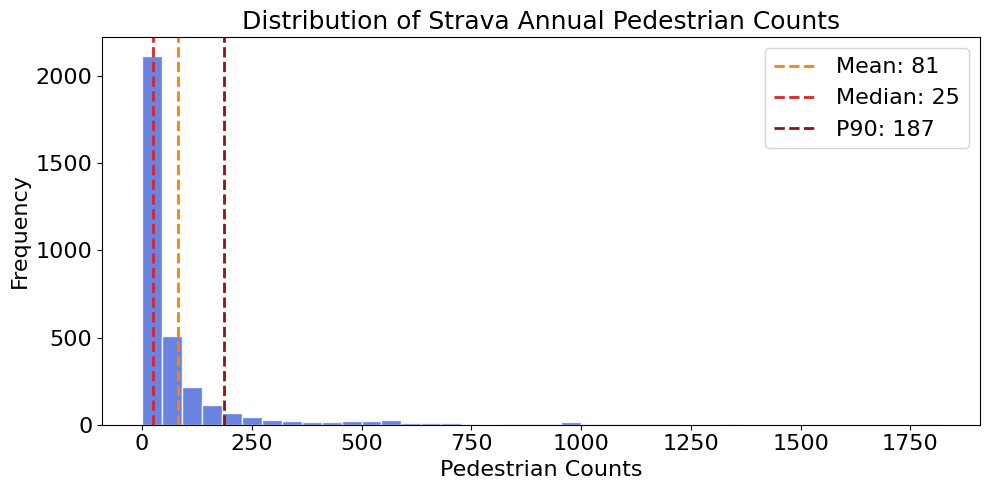

In [3]:
data = dataset['ped_avg']

mean_val = np.mean(data)
median_val = np.median(data)
p90_val = np.percentile(data, 90)  

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(data, bins=40, color="#516ddb", edgecolor="white", alpha=0.85)

ax.axvline(mean_val, color='#ff7f0e', linestyle='--', linewidth=2, label=f"Mean: {mean_val:.0f}")
ax.axvline(median_val, color='#d62728', linestyle='--', linewidth=2, label=f"Median: {median_val:.0f}")
ax.axvline(p90_val, color='#8c1515', linestyle='--', linewidth=2, label=f"P90: {p90_val:.0f}")

TITLE_SIZE = 18
TEXT_SIZE  = 16

ax.set_title("Distribution of Strava Annual Pedestrian Counts", fontsize=TITLE_SIZE)
ax.set_xlabel("Pedestrian Counts", fontsize=TEXT_SIZE)
ax.set_ylabel("Frequency", fontsize=TEXT_SIZE)

ax.tick_params(axis='both', which='major', labelsize=TEXT_SIZE)

ax.legend(fontsize=TEXT_SIZE)

plt.tight_layout()
out_base = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/ped_distribution_P90.png"
plt.savefig(out_base, dpi=300, bbox_inches='tight')
plt.show()

# Multicollinearity test 

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]

X = dataset[selected_columns].copy()
X = X.dropna()

X_const = sm.add_constant(X)

vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]

print(vif_data.sort_values("VIF", ascending=False))

                 Variable       VIF
23      1_practical_1000m  2.747987
17     treecoverden_1000m  2.283978
15          parking_2000m  2.109284
19        5_culture_1000m  2.002862
20        2_natural_1000m  1.997084
18          tree_age_500m  1.876155
7                 MHD5000  1.843347
13           avgSlope_500  1.792064
21  3_accommodation_1000m  1.700371
6                 BtH2000  1.552856
16    train_station_2000m  1.514189
22         4_sports_1000m  1.505078
2              BM_302_100  1.495649
14           popula_1000m  1.491376
0              BM_104_100  1.248042
11                  width  1.183158
8            5_walk_route  1.172855
12              eDiff_500  1.163537
5              BM_501_100  1.156968
10         13_daisy_route  1.128094
9             2_run_route  1.089862
4              BM_402_100  1.066848
1              BM_201_100  1.052108
3              BM_401_100  1.041309


C:\Users\wmv973\AppData\Local\Temp\ipykernel_6760\976881406.py:12: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128204 (\N{PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


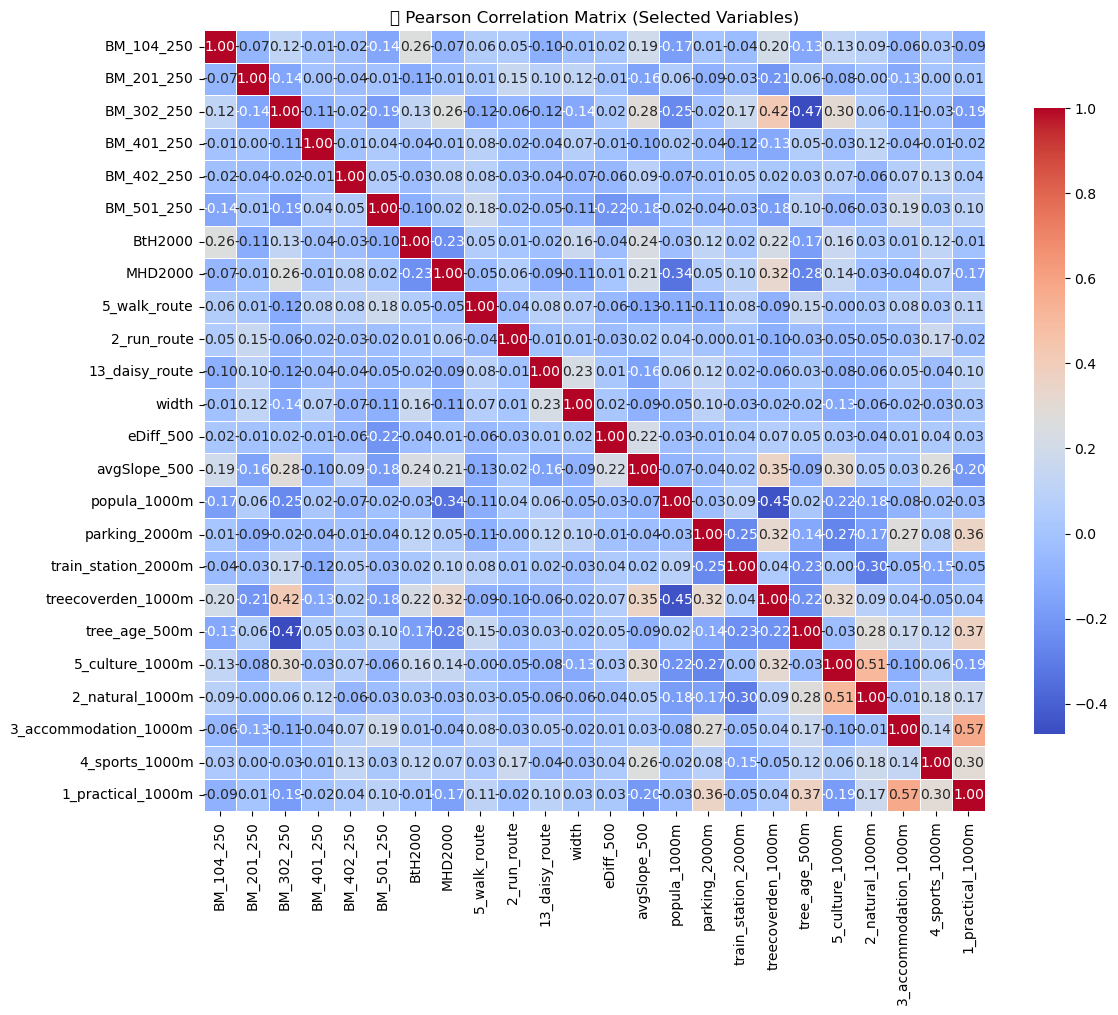

In [ ]:
import seaborn as sns

corr_matrix = dataset[selected_columns].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True,
            cbar_kws={"shrink": .8}, linewidths=0.5)
plt.title("📌 Pearson Correlation Matrix (Selected Variables)")
plt.tight_layout()
plt.show()

# Training

## KNN

In [10]:
selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]
y = dataset['ped_avg']

X_remain, X_test, y_remain, y_test = train_test_split(
    X, y, test_size=0.15, random_state=40
)
joblib.dump(y_test.index, "test_indices_ped.pkl")

cal_rel = 0.15 / 0.85
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(
    X_remain, y_remain, test_size=cal_rel, random_state=40
)
joblib.dump(y_cal.index, "cal_indices_ped.pkl")

kfold = KFold(n_splits=10, shuffle=True, random_state=40)

param_sets = [
    {"n_neighbors": 3, "p": 1},
    {"n_neighbors": 3, "p": 2},
    {"n_neighbors": 4, "p": 1},
    {"n_neighbors": 4, "p": 2},
    {"n_neighbors": 5, "p": 1},
    {"n_neighbors": 5, "p": 2},
]

def eval_one_fold(X_tr, y_tr, X_va, y_va, params):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)

    knn = KNeighborsRegressor(**params)
    knn.fit(X_tr_s, y_tr)

    _, neighbor_idx = knn.kneighbors(X_va_s)
    y_tr_arr = y_tr.to_numpy()
    y_neighbors = y_tr_arr[neighbor_idx]

    y_p05 = np.percentile(y_neighbors, 5,  axis=1)
    y_p50 = np.percentile(y_neighbors, 50, axis=1)
    y_p95 = np.percentile(y_neighbors, 95, axis=1)

    y_true = y_va.to_numpy()

    pinball_p50 = mean_pinball_loss(y_true, y_p50, alpha=0.5)
    mae_p50     = mean_absolute_error(y_true, y_p50)
    r2_p50      = r2_score(y_true, y_p50)
    picp        = np.mean((y_true >= y_p05) & (y_true <= y_p95))
    mpiw        = np.mean(y_p95 - y_p05)

    return pinball_p50, mae_p50, r2_p50, picp, mpiw

def cv_eval_manual_params(X_dev, y_dev, param_sets, kfold):
    rows = []
    for idx, params in enumerate(param_sets):
        pinballs, maes, r2s, picps, mpws = [], [], [], [], []
        for tr_idx, va_idx in kfold.split(X_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            pbl, mae, r2, picp, mpw = eval_one_fold(X_tr, y_tr, X_va, y_va, params)
            pinballs.append(pbl); maes.append(mae); r2s.append(r2); picps.append(picp); mpws.append(mpw)

        rows.append({
            "param_idx": idx,
            "params": params,
            "pinball_p50_mean": float(np.mean(pinballs)),
            "pinball_p50_std":  float(np.std(pinballs)),
            "mae_p50_mean":     float(np.mean(maes)),
            "mae_p50_std":      float(np.std(maes)),
            "r2_p50_mean":      float(np.mean(r2s)),
            "r2_p50_std":       float(np.std(r2s)),
            "picp_mean":        float(np.mean(picps)),
            "picp_std":         float(np.std(picps)),
            "mpiw_mean":        float(np.mean(mpws)),
        })
    return pd.DataFrame(rows)

cv_results = cv_eval_manual_params(X_train_dev, y_train_dev, param_sets, kfold)
print("\n=== K-fold CV results on 70% train-dev (manual params) ===")
print(cv_results)

CHOSEN_IDX = 0
chosen_params = param_sets[CHOSEN_IDX]
print("\nChosen params:", chosen_params)

scaler_final = StandardScaler()
X_train_dev_s = scaler_final.fit_transform(X_train_dev)
knn_final = KNeighborsRegressor(**chosen_params)
knn_final.fit(X_train_dev_s, y_train_dev)

train_dev_payload = {
    "y_train_dev_fit_order": y_train_dev.to_numpy(),  
    "train_dev_index": X_train_dev.index}         
joblib.dump(knn_final, "knn_cqr_ped.pkl")
joblib.dump(scaler_final, "scaler_cqr_ped.pkl")
joblib.dump(train_dev_payload, "train_dev_payload.pkl")
joblib.dump(cv_results, "knn_cqr_cv_results.pkl")



=== K-fold CV results on 70% train-dev (manual params) ===
   param_idx                      params  pinball_p50_mean  pinball_p50_std  \
0          0  {'n_neighbors': 3, 'p': 1}         22.528954         2.364780   
1          1  {'n_neighbors': 3, 'p': 2}         23.077646         2.503182   
2          2  {'n_neighbors': 4, 'p': 1}         22.840578         2.155883   
3          3  {'n_neighbors': 4, 'p': 2}         23.197996         1.998924   
4          4  {'n_neighbors': 5, 'p': 1}         23.191172         2.704054   
5          5  {'n_neighbors': 5, 'p': 2}         24.174171         2.985747   

   mae_p50_mean  mae_p50_std  r2_p50_mean  r2_p50_std  picp_mean  picp_std  \
0     45.057909     4.729560     0.611538    0.089633   0.491156  0.043907   
1     46.155293     5.006364     0.550821    0.144663   0.479413  0.033444   
2     45.681157     4.311766     0.666320    0.091048   0.594408  0.042345   
3     46.395993     3.997848     0.599224    0.097674   0.593522  0.040882

['knn_cqr_cv_results.pkl']

## Random forest

In [18]:
from quantile_forest import RandomForestQuantileRegressor

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]
y = dataset['ped_avg']

X_remain, X_test, y_remain, y_test = train_test_split(
    X, y, test_size=0.15, random_state=40
)
joblib.dump(y_test.index, "test_indices_ped.pkl")

cal_rel = 0.15 / 0.85 
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(
    X_remain, y_remain, test_size=cal_rel, random_state=40
)
joblib.dump(y_cal.index, "cal_indices_ped.pkl")

kfold = KFold(n_splits=10, shuffle=True, random_state=40)

param_sets = [
    {"n_estimators": 300, "max_depth": 10, "min_samples_split": 8, "min_samples_leaf": 4, 'max_features': 0.6, "random_state": 40},
    {"n_estimators": 300, "max_depth": 10, "min_samples_split": 4, "min_samples_leaf": 2, "random_state": 40},
    {"n_estimators": 300, "max_depth": 12, "min_samples_split": 4, "min_samples_leaf": 2, "random_state": 40},
    {"n_estimators": 500, "max_depth": 10, "min_samples_split": 4, "min_samples_leaf": 2, "random_state": 40}
]

def eval_one_fold(X_tr, y_tr, X_va, y_va, params):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)

    qrf = RandomForestQuantileRegressor(default_quantiles=0.5, **params)
    qrf.fit(X_tr_s, y_tr)

    y_p50 = qrf.predict(X_va_s, quantiles=0.5)
    y_p05 = qrf.predict(X_va_s, quantiles=0.05)
    y_p95 = qrf.predict(X_va_s, quantiles=0.95)

    y_true = y_va.to_numpy()

    pinball_p50 = mean_pinball_loss(y_true, y_p50, alpha=0.5)
    mae_p50     = mean_absolute_error(y_true, y_p50)
    r2_p50      = r2_score(y_true, y_p50)
    picp        = float(np.mean((y_true >= y_p05) & (y_true <= y_p95)))
    mpiw        = float(np.mean(y_p95 - y_p05))

    return pinball_p50, mae_p50, r2_p50, picp, mpiw

def cv_eval_manual_params(X_dev, y_dev, param_sets, kfold):
    rows = []
    for idx, params in enumerate(param_sets):
        pinballs, maes, r2s, picps, mpws = [], [], [], [], []
        for tr_idx, va_idx in kfold.split(X_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            pbl, mae, r2, picp, mpw = eval_one_fold(X_tr, y_tr, X_va, y_va, params)
            pinballs.append(pbl); maes.append(mae); r2s.append(r2); picps.append(picp); mpws.append(mpw)
        rows.append({
            "param_idx": idx,
            "params": params,
            "pinball_p50_mean": float(np.mean(pinballs)),
            "pinball_p50_std":  float(np.std(pinballs)),
            "mae_p50_mean":     float(np.mean(maes)),
            "mae_p50_std":      float(np.std(maes)),
            "r2_p50_mean":      float(np.mean(r2s)),
            "r2_p50_std":       float(np.std(r2s)),
            "picp_mean":        float(np.mean(picps)),
            "picp_std":         float(np.std(picps)),
            "mpiw_mean":        float(np.mean(mpws)),
        })
    return pd.DataFrame(rows)

cv_results = cv_eval_manual_params(X_train_dev, y_train_dev, param_sets, kfold)
print("\n=== K-fold CV results on 70% train-dev (manual params, QRF) ===")
print(cv_results)

CHOSEN_IDX = 2
chosen_params = param_sets[CHOSEN_IDX]
print("\nChosen params:", chosen_params)

scaler_final = StandardScaler()
X_train_dev_s = scaler_final.fit_transform(X_train_dev)

qrf_final = RandomForestQuantileRegressor(default_quantiles=0.5, **chosen_params)
qrf_final.fit(X_train_dev_s, y_train_dev)

joblib.dump(qrf_final, "qrf_cqr_ped.pkl")
joblib.dump(scaler_final, "scaler_cqr_ped.pkl")
joblib.dump(cv_results, "qrf_cqr_cv_results.pkl")


=== K-fold CV results on 70% train-dev (manual params, QRF) ===
   param_idx                                             params  \
0          0  {'n_estimators': 300, 'max_depth': 10, 'min_sa...   
1          1  {'n_estimators': 300, 'max_depth': 10, 'min_sa...   
2          2  {'n_estimators': 300, 'max_depth': 12, 'min_sa...   
3          3  {'n_estimators': 500, 'max_depth': 10, 'min_sa...   

   pinball_p50_mean  pinball_p50_std  mae_p50_mean  mae_p50_std  r2_p50_mean  \
0         22.695425         3.330016     45.390850     6.660032     0.605338   
1         21.362829         3.132216     42.725658     6.264432     0.665023   
2         20.702423         2.800384     41.404847     5.600768     0.673299   
3         21.378486         3.112101     42.756972     6.224202     0.664476   

   r2_p50_std  picp_mean  picp_std   mpiw_mean  
0    0.089117   0.963126  0.010308  248.529615  
1    0.126296   0.951854  0.013460  225.558290  
2    0.120042   0.946646  0.011755  217.655060  
3 

['qrf_cqr_cv_results.pkl']

## XGBoost

In [ ]:
import xgboost as xgb

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]
y = dataset['ped_avg']

X_remain, X_test, y_remain, y_test = train_test_split(
    X, y, test_size=0.15, random_state=40
)
joblib.dump(y_test.index, "test_indices_ped.pkl")

cal_rel = 0.15 / 0.85
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(
    X_remain, y_remain, test_size=cal_rel, random_state=40
)
joblib.dump(y_cal.index, "cal_indices_ped.pkl")

kfold = KFold(n_splits=10, shuffle=True, random_state=40)

param_sets = [
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 11, "min_child_weight": 3,
     "subsample": 0.8, "colsample_bytree": 0.9, "reg_lambda": 2.0, "random_state": 40},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 11, "min_child_weight": 3, 
     "subsample": 0.8, "colsample_bytree": 0.9, "reg_lambda": 2.0, "random_state": 40},
    {"n_estimators": 500, "learning_rate": 0.03, "max_depth": 8, "min_child_weight": 6,
     "subsample": 0.8, "colsample_bytree": 0.7, "reg_lambda": 2.0, "random_state": 40}
]

def _fit_one_quantile(X_tr_s, y_tr, X_va_s, base_params, q):
    model = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=q,
        eval_metric='mae',
        **base_params
    )
    model.fit(X_tr_s, y_tr)
    return model, model.predict(X_va_s)

def eval_one_fold(X_tr, y_tr, X_va, y_va, params):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)

    m05, y_p05 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.05)
    m50, y_p50 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.50)
    m95, y_p95 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.95)

    y_true = y_va.to_numpy()

    pinball_p50 = mean_pinball_loss(y_true, y_p50, alpha=0.5)
    mae_p50     = mean_absolute_error(y_true, y_p50)
    r2_p50      = r2_score(y_true, y_p50)
    picp        = float(np.mean((y_true >= y_p05) & (y_true <= y_p95)))
    mpiw        = float(np.mean(y_p95 - y_p05))

    return pinball_p50, mae_p50, r2_p50, picp, mpiw

def cv_eval_manual_params(X_dev, y_dev, param_sets, kfold):
    rows = []
    for idx, params in enumerate(param_sets):
        pinballs, maes, r2s, picps, mpws = [], [], [], [], []
        for tr_idx, va_idx in kfold.split(X_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            pbl, mae, r2, picp, mpw = eval_one_fold(X_tr, y_tr, X_va, y_va, params)
            pinballs.append(pbl); maes.append(mae); r2s.append(r2); picps.append(picp); mpws.append(mpw)
        rows.append({
            "param_idx": idx,
            "params": params,
            "pinball_p50_mean": float(np.mean(pinballs)),
            "pinball_p50_std":  float(np.std(pinballs)),
            "mae_p50_mean":     float(np.mean(maes)),
            "mae_p50_std":      float(np.std(maes)),
            "r2_p50_mean":      float(np.mean(r2s)),
            "r2_p50_std":       float(np.std(r2s)),
            "picp_mean":        float(np.mean(picps)),
            "picp_std":         float(np.std(picps)),
            "mpiw_mean":        float(np.mean(mpws)),
        })
    return pd.DataFrame(rows)

cv_results = cv_eval_manual_params(X_train_dev, y_train_dev, param_sets, kfold)
print("\n=== K-fold CV results on 70% train-dev (manual params, XGB-CQR base) ===")
print(cv_results)

CHOSEN_IDX = 1
chosen_params = param_sets[CHOSEN_IDX]
print("\nChosen params:", chosen_params)

scaler_final = StandardScaler()
X_train_dev_s = scaler_final.fit_transform(X_train_dev)

xgb_models = {}
for q in (0.05, 0.50, 0.95):
    m = xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=q,
        eval_metric='mae',
        **chosen_params
    )
    m.fit(X_train_dev_s, y_train_dev)
    xgb_models[q] = m

joblib.dump(xgb_models, "xgb_cqr_ped_1.pkl") 
joblib.dump(scaler_final, "scaler_cqr_ped.pkl")
joblib.dump(cv_results, "xgb_cqr_cv_results_1.pkl")


=== K-fold CV results on 70% train-dev (manual params, XGB-CQR base) ===
   param_idx                                             params  \
0          0  {'n_estimators': 300, 'learning_rate': 0.05, '...   
1          1  {'n_estimators': 500, 'learning_rate': 0.05, '...   
2          2  {'n_estimators': 500, 'learning_rate': 0.05, '...   
3          3  {'n_estimators': 500, 'learning_rate': 0.03, '...   

   pinball_p50_mean  pinball_p50_std  mae_p50_mean  mae_p50_std  r2_p50_mean  \
0         23.187892         1.382842     46.375784     2.765685     0.683229   
1         25.113617         2.715640     50.227234     5.431279     0.554979   
2         23.077459         1.338912     46.154918     2.677824     0.691802   
3         23.511902         2.056013     47.023804     4.112025     0.629743   

   r2_p50_std  picp_mean  picp_std   mpiw_mean  
0    0.056098   0.657758  0.041846  130.471246  
1    0.087908   0.845157  0.029800  174.723671  
2    0.057993   0.617843  0.039551  124.14

['xgb_cqr_cv_results_1.pkl']

## LightGBM

In [ ]:
import lightgbm as lgb

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]
y = dataset['ped_avg']

X_remain, X_test, y_remain, y_test = train_test_split(X, y, test_size=0.15, random_state=40)
joblib.dump(y_test.index, "test_indices_ped.pkl")

cal_rel = 0.15 / 0.85
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(X_remain, y_remain, test_size=cal_rel, random_state=40)
joblib.dump(y_cal.index, "cal_indices_ped.pkl")

def to_scaled_df(scaler, X_df, fit=False):
    arr = scaler.fit_transform(X_df) if fit else scaler.transform(X_df)
    return pd.DataFrame(arr, index=X_df.index, columns=X_df.columns)

kfold = KFold(n_splits=10, shuffle=True, random_state=40)
param_sets = [
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 13, "min_child_samples": 10,
     "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 2.0, "random_state": 40},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 13, "min_child_samples": 4,
     "subsample": 0.8, "colsample_bytree": 0.8, "reg_lambda": 2.0, "random_state": 40},
    {"n_estimators": 700, "learning_rate": 0.03, "max_depth": 9,  "min_child_samples": 20,
     "subsample": 0.8, "colsample_bytree": 0.7, "reg_lambda": 2.0, "random_state": 40},
]

def _fit_one_quantile(X_tr_s, y_tr, X_va_s, base_params, q):
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, verbose=-1, **base_params)
    m.fit(X_tr_s, y_tr)
    return m, m.predict(X_va_s)

def eval_one_fold(X_tr, y_tr, X_va, y_va, params):
    scaler = StandardScaler()
    X_tr_s = to_scaled_df(scaler, X_tr, fit=True)   
    X_va_s = to_scaled_df(scaler, X_va, fit=False) 

    m05, y_p05 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.05)
    m50, y_p50 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.50)
    m95, y_p95 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.95)
    y_true = y_va.to_numpy()
    return (mean_pinball_loss(y_true, y_p50, alpha=0.5),
            mean_absolute_error(y_true, y_p50),
            r2_score(y_true, y_p50),
            float(np.mean((y_true >= y_p05) & (y_true <= y_p95))),
            float(np.mean(y_p95 - y_p05)))

def cv_eval_manual_params(X_dev, y_dev, param_sets, kfold):
    rows = []
    for idx, params in enumerate(param_sets):
        pinballs, maes, r2s, picps, mpws = [], [], [], [], []
        for tr_idx, va_idx in kfold.split(X_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            pbl, mae, r2, picp, mpw = eval_one_fold(X_tr, y_tr, X_va, y_va, params)
            pinballs.append(pbl); maes.append(mae); r2s.append(r2); picps.append(picp); mpws.append(mpw)
        rows.append({
            "param_idx": idx, "params": params,
            "pinball_p50_mean": float(np.mean(pinballs)),
            "mae_p50_mean": float(np.mean(maes)),
            "r2_p50_mean": float(np.mean(r2s)),
            "picp_mean": float(np.mean(picps)),
            "mpiw_mean": float(np.mean(mpws)),
        })
    return pd.DataFrame(rows)

cv_results = cv_eval_manual_params(X_train_dev, y_train_dev, param_sets, kfold)
print("\n=== K-fold CV on 70% (LGBM-CQR base) ===")
print(cv_results)

# 4) 训练“终模型”（70%）并保存为 dict
CHOSEN_IDX = 0
chosen_params = param_sets[CHOSEN_IDX]
scaler_final = StandardScaler()
X_train_dev_s = to_scaled_df(scaler_final, X_train_dev, fit=True) 

lgb_models = {}
for q in (0.05, 0.50, 0.95):
    m = lgb.LGBMRegressor(objective="quantile", alpha=q, verbose=-1, **chosen_params)
    m.fit(X_train_dev_s, y_train_dev)
    lgb_models[q] = m

joblib.dump(lgb_models, "lgb_cqr_ped.pkl")
joblib.dump(scaler_final, "scaler_cqr_ped.pkl")
joblib.dump(cv_results, "lgb_cqr_cv_results.pkl")



=== K-fold CV on 70% (LGBM-CQR base) ===
   param_idx                                             params  \
0          0  {'n_estimators': 500, 'learning_rate': 0.05, '...   
1          1  {'n_estimators': 500, 'learning_rate': 0.05, '...   
2          2  {'n_estimators': 700, 'learning_rate': 0.03, '...   

   pinball_p50_mean  mae_p50_mean  r2_p50_mean  picp_mean   mpiw_mean  
0         22.918179     45.836359     0.621355   0.696800  139.936554  
1         22.769145     45.538290     0.643721   0.684199  138.660328  
2         24.387231     48.774461     0.564161   0.699392  149.664236  


['lgb_cqr_cv_results.pkl']

## Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]; y = dataset['ped_avg']

X_remain, X_test, y_remain, y_test = train_test_split(X, y, test_size=0.15, random_state=40)
joblib.dump(y_test.index, "test_indices_ped.pkl")
cal_rel = 0.15 / 0.85
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(X_remain, y_remain, test_size=cal_rel, random_state=40)
joblib.dump(y_cal.index, "cal_indices_ped.pkl")

kfold = KFold(n_splits=10, shuffle=True, random_state=40)
param_sets = [
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 13, "min_samples_leaf": 10, "subsample": 0.8, "random_state": 40},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 13, "min_samples_leaf": 4, "subsample": 0.8, "random_state": 40},
    {"n_estimators": 500, "learning_rate": 0.03, "max_depth": 9,  "min_samples_leaf": 10, "subsample": 0.8, "random_state": 40},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 13,  "min_samples_leaf": 10, "subsample": 0.8, "random_state": 40},
]

def _fit_one_quantile(X_tr_s, y_tr, X_va_s, base_params, q):
    m = GradientBoostingRegressor(loss="quantile", alpha=q, **base_params)
    m.fit(X_tr_s, y_tr)
    return m, m.predict(X_va_s)

def eval_one_fold(X_tr, y_tr, X_va, y_va, params):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr); X_va_s = scaler.transform(X_va)
    m05, y_p05 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.05)
    m50, y_p50 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.50)
    m95, y_p95 = _fit_one_quantile(X_tr_s, y_tr, X_va_s, params, 0.95)
    y_true = y_va.to_numpy()
    return (mean_pinball_loss(y_true, y_p50, alpha=0.5),
            mean_absolute_error(y_true, y_p50),
            r2_score(y_true, y_p50),
            float(np.mean((y_true >= y_p05) & (y_true <= y_p95))),
            float(np.mean(y_p95 - y_p05)))

def cv_eval_manual_params(X_dev, y_dev, param_sets, kfold):
    rows=[]
    for idx, params in enumerate(param_sets):
        pinballs, maes, r2s, picps, mpws = [], [], [], [], []
        for tr_idx, va_idx in kfold.split(X_dev):
            X_tr, X_va = X_dev.iloc[tr_idx], X_dev.iloc[va_idx]
            y_tr, y_va = y_dev.iloc[tr_idx], y_dev.iloc[va_idx]
            pbl, mae, r2, picp, mpw = eval_one_fold(X_tr, y_tr, X_va, y_va, params)
            pinballs.append(pbl); maes.append(mae); r2s.append(r2); picps.append(picp); mpws.append(mpw)
        rows.append({"param_idx": idx, "params": params,
                     "pinball_p50_mean": float(np.mean(pinballs)),
                     "mae_p50_mean": float(np.mean(maes)),
                     "r2_p50_mean": float(np.mean(r2s)),
                     "picp_mean": float(np.mean(picps)),
                     "mpiw_mean": float(np.mean(mpws))})
    return pd.DataFrame(rows)

cv_results = cv_eval_manual_params(X_train_dev, y_train_dev, param_sets, kfold)
print("\n=== K-fold CV on 70% (GBRT-CQR base) ==="); print(cv_results)

CHOSEN_IDX = 0
chosen_params = param_sets[CHOSEN_IDX]
scaler_final = StandardScaler()
X_train_dev_s = scaler_final.fit_transform(X_train_dev)

gbrt_models = {}
for q in (0.05, 0.50, 0.95):
    m = GradientBoostingRegressor(loss="quantile", alpha=q, **chosen_params)
    m.fit(X_train_dev_s, y_train_dev)
    gbrt_models[q] = m

joblib.dump(gbrt_models, "gbrt_cqr_ped.pkl")
joblib.dump(scaler_final, "scaler_cqr_ped.pkl")
joblib.dump(cv_results, "gbrt_cqr_cv_results.pkl")


=== K-fold CV on 70% (GBRT-CQR base) ===
   param_idx                                             params  \
0          0  {'n_estimators': 500, 'learning_rate': 0.05, '...   
1          1  {'n_estimators': 500, 'learning_rate': 0.05, '...   
2          2  {'n_estimators': 500, 'learning_rate': 0.03, '...   
3          3  {'n_estimators': 300, 'learning_rate': 0.03, '...   

   pinball_p50_mean  mae_p50_mean  r2_p50_mean  picp_mean   mpiw_mean  
0         22.883474     45.766948     0.638836   0.854677  157.562859  
1         22.904285     45.808570     0.664448   0.823429  136.848343  
2         23.226935     46.453869     0.608032   0.868558  162.243282  
3         23.664079     47.328157     0.594958   0.886352  166.012151  


['gbrt_cqr_cv_results.pkl']

# Model selection

### Moran's I

In [ ]:
from libpysal.weights import KNN as KNN_W
from libpysal.weights.spatial_lag import lag_spatial
from esda.moran import Moran

def moran_scatterplot_no_splot(
    y, w, moran_obj=None,
    title="Moran scatterplot",
    xlabel="Standardized residuals",
    ylabel="Spatial lag of residuals",
    figsize=(6, 6),
    point_size=12,
    alpha=0.7
):
    y = np.asarray(y, dtype=float).ravel()
    if len(y) < 3:
        raise ValueError("样本太少，无法绘制 Moran scatterplot。")

    y_z = (y - y.mean()) / (y.std(ddof=0) + 1e-12)
    wy = lag_spatial(w, y_z)

    if moran_obj is None:
        moran_obj = Moran(y, w)

    I = float(moran_obj.I)
    p = float(moran_obj.p_sim)

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(y_z, wy, s=point_size, alpha=alpha)

    xline = np.linspace(np.min(y_z), np.max(y_z), 200)
    ax.plot(xline, I * xline)

    ax.axhline(0, linewidth=1)
    ax.axvline(0, linewidth=1)

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f"{title}\nI={I:.4f}, p_sim={p:.4g}")
    plt.tight_layout()
    return fig, ax

FILEMAP_CQR = {
    "KNN":  "knn_cqr_ped.pkl",
    "QRF":  "qrf_cqr_ped.pkl",
    "XGB":  "xgb_cqr_ped.pkl",
    "LGB":  "lgb_cqr_ped.pkl",
    "GBRT": "gbrt_cqr_ped.pkl",
}
MORAN_LABELS_CQR = {
    "KNN":  "knn_cqr",
    "QRF":  "qrf_cqr",
    "XGB":  "xgb_cqr",
    "LGB":  "lgb_cqr",
    "GBRT": "gbrt_cqr",
}

scaler_final = joblib.load("scaler_cqr_ped.pkl")

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]

X_all = dataset[features]
y_all = dataset["ped_avg"]

X_remain, X_test, y_remain, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=40
)
cal_rel = 0.15 / 0.85
X_train_dev, X_cal, y_train_dev, y_cal = train_test_split(
    X_remain, y_remain, test_size=cal_rel, random_state=40
)

X_train_dev_s = scaler_final.transform(X_train_dev)

if not {"longitude", "latitude"}.issubset(dataset.columns):
    raise KeyError("dataset 中缺少 'longitude' 或 'latitude' 列。")

coords = dataset.loc[X_train_dev.index, ["longitude", "latitude"]].to_numpy()
k = min(12, max(1, len(X_train_dev) - 1))
w = KNN_W.from_array(coords, k=k)
w.transform = "r"

def _get(mdict, q):
    if q in mdict: return mdict[q]
    qs = str(q)
    if qs in mdict: return mdict[qs]
    q100 = int(round(q * 100))
    if q100 in mdict: return mdict[q100]
    qs2 = str(q100)
    if qs2 in mdict: return mdict[qs2]
    raise KeyError(f"quantile key {q} not found. keys={list(mdict.keys())[:10]}...")

def predict_p50(algo, model_obj, Xs):
    name = algo.upper()
    if name == "KNN":
        _, neighbor_idx = model_obj.kneighbors(Xs)
        y_train_used = np.asarray(model_obj._y).reshape(-1)
        y_neighbors  = y_train_used[neighbor_idx]
        return np.percentile(y_neighbors, 50, axis=1)
    if name == "QRF":
        return model_obj.predict(Xs, quantiles=0.50)
    if name in ("XGB", "LGB", "GBRT"):
        return _get(model_obj, 0.50).predict(Xs)
    raise ValueError(f"Unknown model type: {algo}")

OUT_DIR = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance"
os.makedirs(OUT_DIR, exist_ok=True)

DO_PLOT = False  

for algo, fpath in FILEMAP_CQR.items():
    label = MORAN_LABELS_CQR[algo]
    out_csv = os.path.join(OUT_DIR, f"moran_results_{label}.csv")

    try:
        model = joblib.load(fpath)

        p50_train = predict_p50(algo, model, X_train_dev_s)
        residuals = (y_train_dev.to_numpy() - np.asarray(p50_train)).ravel()

        moran = Moran(residuals, w)
        moran_abs = Moran(np.abs(residuals), w)

        row = pd.DataFrame([{
            "model": algo,
            "method": "CQR",
            "training_split": "train_dev",
            "k_neighbors": int(k),
            "moran_I": float(moran.I),
            "p_value": float(moran.p_sim),
            "z_score": float(moran.z_norm),
            "moran_I_abs": float(moran_abs.I),
            "p_value_abs": float(moran_abs.p_sim),
            "n": int(len(X_train_dev))
        }])

        row.to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
        print(f"[{algo}] Moran saved -> {out_csv} | I={moran.I:.4f}, p={moran.p_sim:.4g}")

        if DO_PLOT:
            fig, ax = moran_scatterplot_no_splot(
                residuals, w, moran_obj=moran,
                title=f"Moran's I Scatterplot ({algo} CQR residuals on train_dev, k={k})"
            )
            plt.show()

    except Exception as e:
        print(f"[{algo}] ERROR -> {type(e).__name__}: {e}")


[KNN] Moran saved -> /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance\moran_results_knn_cqr.csv | I=0.0123, p=0.05
[QRF] Moran saved -> /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance\moran_results_qrf_cqr.csv | I=0.0278, p=0.005
[XGB] Moran saved -> /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance\moran_results_xgb_cqr.csv | I=0.0389, p=0.003


c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LGB] Moran saved -> /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance\moran_results_lgb_cqr.csv | I=0.1400, p=0.001
[GBRT] Moran saved -> /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance\moran_results_gbrt_cqr.csv | I=0.1237, p=0.001


### Calibration

In [ ]:
import numpy as np
import pandas as pd
import joblib

scaler_final = joblib.load("scaler_cqr_ped.pkl")
cal_indices  = joblib.load("cal_indices_ped.pkl")

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]

X_cal = dataset.loc[cal_indices, features]
y_cal = dataset.loc[cal_indices, 'ped_avg'].to_numpy()
X_cal_s = scaler_final.transform(X_cal)


def conformal_qhat(scores, alpha):
    s = np.sort(scores)
    n = len(s)
    k = int(np.ceil((n + 1) * (1 - alpha))) - 1
    k = min(max(k, 0), n - 1)
    return float(s[k])

def picp(y, lo, up): return float(np.mean((y >= lo) & (y <= up)))
def mpiw(lo, up):    return float(np.mean(up - lo))


cov = 0.90
alpha = 1.0 - cov


MODEL_SPECS = [
    ("KNN",  "knn_cqr_ped.pkl",  "cqr_calibration_qhats_knn.pkl"),
    ("QRF",  "qrf_cqr_ped.pkl",  "cqr_calibration_qhats_QRF.pkl"),
    ("XGB",  "xgb_cqr_ped.pkl",  "cqr_calibration_qhats_XGBoost.pkl"),
    ("LGB",  "lgb_cqr_ped.pkl",  "cqr_calibration_qhats_LightGBM.pkl"),
    ("GBRT", "gbrt_cqr_ped.pkl", "cqr_calibration_qhats_GBRT.pkl"),
]

for name, model_path, out_qhat_path in MODEL_SPECS:
    name_u = name.upper()
    print(f"\n================ {name_u} =================")

    model_obj = joblib.load(model_path)

    
    if name_u == "KNN":
        _, neighbor_idx = model_obj.kneighbors(X_cal_s)
        y_train_used = np.asarray(model_obj._y).reshape(-1)
        y_neighbors  = y_train_used[neighbor_idx]
        p05 = np.percentile(y_neighbors, 5,  axis=1)
        p95 = np.percentile(y_neighbors, 95, axis=1)

    elif name_u == "QRF":
        p05 = model_obj.predict(X_cal_s, quantiles=0.05)
        p95 = model_obj.predict(X_cal_s, quantiles=0.95)

    elif name_u in ("XGB", "LGB", "GBRT"):
        # dict: {0.05: model, 0.5: model, 0.95: model}
        p05 = model_obj[0.05].predict(X_cal_s)
        p95 = model_obj[0.95].predict(X_cal_s)

    else:
        raise ValueError(f"Unknown model: {name}")

    # ---- split conformal scores ----
    scores = np.maximum(p05 - y_cal, y_cal - p95)

    print("\n--- original (without calibration) ---")
    print(f"PICP(cal): {picp(y_cal, p05, p95):.3f} | MPIW(cal): {mpiw(p05, p95):.3f}")

    q_hat = conformal_qhat(scores, alpha)

    p05_c = np.maximum(p05 - q_hat, 0.0)
    p95_c = p95 + q_hat

    print(f"\n=== coverage {int(cov*100)}% ===")
    print(f"q_hat = {q_hat:.6f}")
    print(f"PICP(cal, calibrated): {picp(y_cal, p05_c, p95_c):.3f}")
    print(f"MPIW(cal, calibrated): {mpiw(p05_c, p95_c):.3f}")

    joblib.dump({"q_hat_90": q_hat}, out_qhat_path)
    print(f"Saved: {out_qhat_path}")


================ KNN =================

--- original (without calibration) ---
PICP(cal): 0.496 | MPIW(cal): 79.785

=== coverage 90% ===
q_hat = 30.500000
PICP(cal, calibrated): 0.903
MPIW(cal, calibrated): 123.716
Saved: cqr_calibration_qhats_knn.pkl

================ QRF =================

--- original (without calibration) ---
PICP(cal): 0.957 | MPIW(cal): 195.942

=== coverage 90% ===
q_hat = 0.000000
PICP(cal, calibrated): 0.957
MPIW(cal, calibrated): 195.942
Saved: cqr_calibration_qhats_QRF.pkl

================ XGB =================

--- original (without calibration) ---
PICP(cal): 0.615 | MPIW(cal): 107.248

=== coverage 90% ===
q_hat = 15.668892
PICP(cal, calibrated): 0.903
MPIW(cal, calibrated): 131.050
Saved: cqr_calibration_qhats_XGBoost.pkl

================ LGB =================

--- original (without calibration) ---
PICP(cal): 0.713 | MPIW(cal): 125.163

=== coverage 90% ===
q_hat = 6.628978
PICP(cal, calibrated): 0.903
MPIW(cal, calibrated): 135.621
Saved: cqr_calib

c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


### Model performance

In [ ]:
def compute_test_metrics(y_true, p05, p50, p95):
    y_true = np.asarray(y_true)
    p05 = np.asarray(p05); p50 = np.asarray(p50); p95 = np.asarray(p95)
    return {
        "test_R2":  r2_score(y_true, p50),
        "test_MAE": mean_absolute_error(y_true, p50),
        "test_pinball_05": mean_pinball_loss(y_true, p05, alpha=0.05),
        "test_pinball_50": mean_pinball_loss(y_true, p50, alpha=0.50),
        "test_pinball_95": mean_pinball_loss(y_true, p95, alpha=0.95),
    }

def compute_interval_metrics(y_true, lo, up):
    y_true = np.asarray(y_true)
    lo = np.asarray(lo); up = np.asarray(up)
    picp = float(np.mean((y_true >= lo) & (y_true <= up)))
    mpiw = float(np.mean(up - lo))
    return picp, mpiw

def predict_cqr(model_name, model_obj, Xs):
    name = model_name.upper()
    if name == "KNN":
        _, neighbor_idx = model_obj.kneighbors(Xs)
        y_train_used = np.asarray(model_obj._y).reshape(-1)
        y_neighbors  = y_train_used[neighbor_idx]
        p05 = np.percentile(y_neighbors,  5, axis=1)
        p50 = np.percentile(y_neighbors, 50, axis=1)
        p95 = np.percentile(y_neighbors, 95, axis=1)
        return p05, p50, p95
    if name == "QRF":
        p05 = model_obj.predict(Xs, quantiles=0.05)
        p50 = model_obj.predict(Xs, quantiles=0.50)
        p95 = model_obj.predict(Xs, quantiles=0.95)
        return p05, p50, p95
    if name in ("XGB", "LGB", "GBRT"):
        p05 = model_obj[0.05].predict(Xs)
        p50 = model_obj[0.50].predict(Xs)
        p95 = model_obj[0.95].predict(Xs)
        return p05, p50, p95
    raise ValueError(f"Unknown model type: {model_name}")

def load_qhat_90(qhat_file):
    d = joblib.load(qhat_file)
    if isinstance(d, dict) and "q_hat_90" in d:
        return float(d["q_hat_90"])
    if isinstance(d, dict) and "q_hat_80" in d:
        return float(d["q_hat_80"])
    return 0.0

def apply_cqr_interval(p05, p95, qhat, clip_zero=True):

    lower = np.asarray(p05) - qhat
    if clip_zero:
        lower = np.maximum(lower, 0.0)
    upper = np.asarray(p95) + qhat
    return lower, upper

MORAN_DIR = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/model performance"

def load_moran_two_fields(model_label):
    """
    读取 moran_results_{model_label}.csv 的最后一行，返回 (moran_I, p_value)。
    如 'gbrt_cqr' -> moran_results_gbrt_cqr.csv
    """
    path = os.path.join(MORAN_DIR, f"moran_results_{model_label}.csv")
    df = pd.read_csv(path)
    last = df.iloc[-1]
    return float(last["moran_I"]), float(last["p_value"])


selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]
X = dataset[features]
y = dataset['ped_avg']

test_indices = joblib.load("test_indices_ped.pkl")
X_test = X.loc[test_indices]
y_test = y.loc[test_indices]

scaler_cqr = joblib.load("scaler_cqr_ped.pkl")
X_test_cqr_s = scaler_cqr.transform(X_test)


FILEMAP_CQR = {
    "KNN":  "knn_cqr_ped.pkl",
    "QRF":  "qrf_cqr_ped.pkl",
    "XGB":  "xgb_cqr_ped.pkl",
    "LGB":  "lgb_cqr_ped.pkl",
    "GBRT": "gbrt_cqr_ped.pkl",
}
QHAT_FILES = {
    "KNN":  "cqr_calibration_qhats_knn.pkl",
    "QRF":  "cqr_calibration_qhats_QRF.pkl",
    "XGB":  "cqr_calibration_qhats_XGBoost.pkl",
    "LGB":  "cqr_calibration_qhats_LightGBM.pkl",
    "GBRT": "cqr_calibration_qhats_GBRT.pkl",
}

MORAN_LABELS_CQR = {
    "KNN":  "knn_cqr",
    "QRF":  "qrf_cqr",
    "XGB":  "xgb_cqr",
    "LGB":  "lgb_cqr",
    "GBRT": "gbrt_cqr",
}

rows_cqr = []

for algo, fpath in FILEMAP_CQR.items():
    try:
        model = joblib.load(fpath)

        p05_te, p50_te, p95_te = predict_cqr(algo, model, X_test_cqr_s)

        test_metrics = compute_test_metrics(y_test, p05_te, p50_te, p95_te)

        test_PICP_orig, test_MPIW_orig = compute_interval_metrics(y_test, p05_te, p95_te)

        qhat = load_qhat_90(QHAT_FILES[algo])
        p05_te_c, p95_te_c = apply_cqr_interval(p05_te, p95_te, qhat, clip_zero=True)
        test_PICP_cqr, test_MPIW_cqr = compute_interval_metrics(y_test, p05_te_c, p95_te_c)

        moran_I, p_val = load_moran_two_fields(MORAN_LABELS_CQR[algo])

        row = {
            "model": algo,
            **test_metrics,
            # Moran
            "moran_I": moran_I,
            "p_value": p_val,
            
            "test_PICP_orig": test_PICP_orig,
            "test_MPIW_orig": test_MPIW_orig,
            
            "test_PICP_cqr": test_PICP_cqr,
            "test_MPIW_cqr": test_MPIW_cqr,
            "q_hat_90": qhat,
        }
        rows_cqr.append(row)

    except Exception as e:
        rows_cqr.append({"model": algo, "error": str(e)})

df_cqr_summary = pd.DataFrame(rows_cqr).set_index("model").sort_index()

print("\n=== CQR TEST summary: predictive metrics + intervals + Moran's I ===")
print(df_cqr_summary)


out_path = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/cqr_test_moran_summary.csv"
df_cqr_summary.to_csv(out_path, index=True)


c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



=== CQR TEST summary: predictive metrics + intervals + Moran's I ===
        test_R2   test_MAE  test_pinball_05  test_pinball_50  test_pinball_95  \
model                                                                           
GBRT   0.621505  42.023925         3.919939        21.011962        13.530075   
KNN    0.545390  45.327935         6.536285        22.663968        13.826751   
LGB    0.634697  41.219500         3.997771        20.609750        13.761531   
QRF    0.658016  37.577935         3.534236        18.788968         9.777085   
XGB    0.654882  43.007628         4.297664        21.503814        16.051768   

        moran_I  p_value  test_PICP_orig  test_MPIW_orig  test_PICP_cqr  \
model                                                                     
GBRT   0.115689    0.001        0.807692      152.171062       0.874494   
KNN    0.012348    0.046        0.477733       81.021862       0.894737   
LGB    0.132390    0.001        0.692308      141.412382      

### interval visualization

c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\pickle.py:1835: UserWarning: [11:58:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\data\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


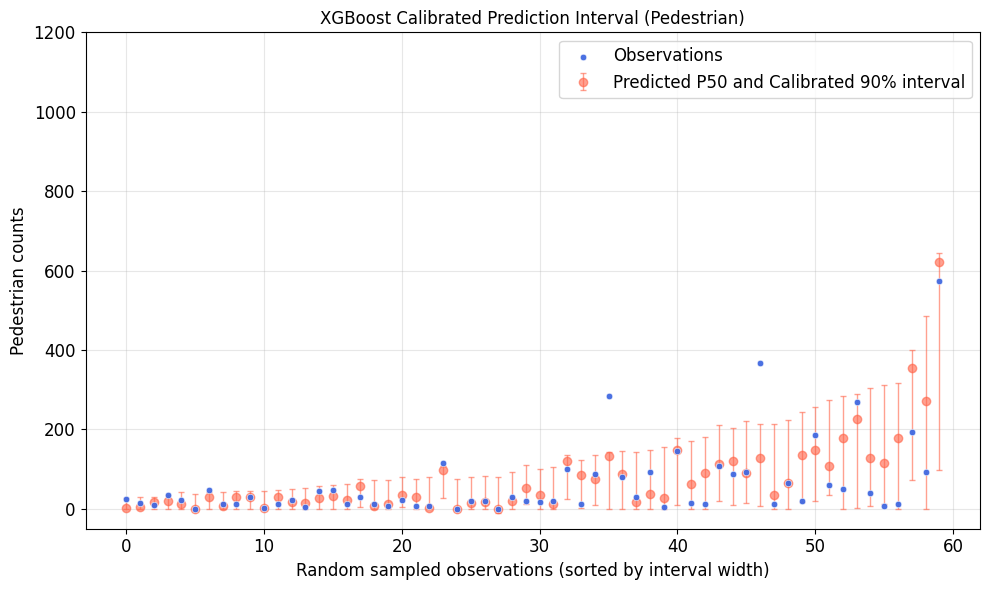

In [ ]:
xgb_models   = joblib.load("xgb_cqr_ped.pkl")          # {0.05: model, 0.5: model, 0.95: model}
scaler_final = joblib.load("scaler_cqr_ped.pkl")
test_indices = joblib.load("test_indices_ped.pkl")
qhats_dict   = joblib.load("cqr_calibration_qhats_XGBoost.pkl")  # {"q_hat_80":..., "q_hat_90":...}


target_cov = 0.90
q_hat_key  = f"q_hat_{int(target_cov*100)}"
q_hat      = float(qhats_dict[q_hat_key])

feat_cols = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in feat_cols if c in dataset.columns]

def subset_by_indices(df, indices):
    indices = np.asarray(indices)
    # boolean mask
    if indices.dtype == bool:
        return df.loc[indices]
    # if matches index labels -> loc, else fallback to iloc
    try:
        return df.loc[indices]
    except Exception:
        return df.iloc[indices]


X_test = subset_by_indices(dataset[features], test_indices)
y_test = subset_by_indices(dataset['ped_avg'], test_indices)
X_test_s = scaler_final.transform(X_test)


p05 = xgb_models[0.05].predict(X_test_s)
p50 = xgb_models[0.5].predict(X_test_s)
p95 = xgb_models[0.95].predict(X_test_s)


p05_c = np.maximum(p05 - q_hat, 0.0)
p95_c = p95 + q_hat

df_plot_full = (
    pd.DataFrame({
        "y_true": np.asarray(y_test),
        "y_p05":  p05_c,
        "y_p50":  p50,
        "y_p95":  p95_c
    }, index=X_test.index)
    .dropna()
)

q_arr = np.vstack([
    df_plot_full["y_p05"].to_numpy(),
    df_plot_full["y_p50"].to_numpy(),
    df_plot_full["y_p95"].to_numpy()
]).T
q_sorted = np.sort(q_arr, axis=1)
df_plot_full["y_p05"] = q_sorted[:, 0]
df_plot_full["y_p50"] = q_sorted[:, 1]
df_plot_full["y_p95"] = q_sorted[:, 2]

n_sample = min(60, len(df_plot_full))
df_plot = (
    df_plot_full
    .sample(n=n_sample, random_state=40)
    .reset_index(drop=True)
)
df_plot["p95_p05"] = df_plot["y_p95"] - df_plot["y_p05"]
df_plot.sort_values(by="p95_p05", inplace=True)
df_plot = df_plot.reset_index(drop=True)

def picp(y, lo, up): return float(np.mean((y >= lo) & (y <= up)))
def mpiw(lo, up):    return float(np.mean(up - lo))

PICP_test = picp(df_plot_full["y_true"].to_numpy(),
                 df_plot_full["y_p05"].to_numpy(),
                 df_plot_full["y_p95"].to_numpy())
MPIW_test = mpiw(df_plot_full["y_p05"].to_numpy(),
                 df_plot_full["y_p95"].to_numpy())

FONT_SIZE = 12

x_axis = np.arange(len(df_plot))
plt.figure(figsize=(10, 6))

err1 = - df_plot["y_p05"] + df_plot["y_p50"]
err2 = df_plot["y_p95"] - df_plot["y_p50"]
err = np.array(list(zip(err1, err2))).T

pred_handle = plt.errorbar(
    x_axis, df_plot["y_p50"], yerr=err, fmt='o',
    color="tomato", ecolor="tomato",
    alpha=0.6, elinewidth=1, capsize=2,
    label="Predicted P50 and Calibrated 90% interval",
    zorder=2
)

obs_handle = plt.scatter(
    x_axis, df_plot["y_true"],
    s=22, color="royalblue", edgecolor="white", linewidth=0.4,
    alpha=0.95, label="Observations",
    zorder=3
)

plt.xlabel("Random sampled observations (sorted by interval width)", fontsize=FONT_SIZE)
plt.ylabel("Pedestrian counts", fontsize=FONT_SIZE)

plt.title("XGBoost Calibrated Prediction Interval (Pedestrian)", fontsize=FONT_SIZE)

plt.xticks(fontsize=FONT_SIZE)
plt.yticks(fontsize=FONT_SIZE)
plt.grid(True, alpha=0.3)

plt.legend(
    handles=[obs_handle, pred_handle],
    labels=["Observations", "Predicted P50 and Calibrated 90% interval"],
    loc="best",
    fontsize=FONT_SIZE
)

plt.ylim(-50, 1200)
plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/XGBoost_CQR_interval_errorbar_sample60_TEST.png",
    dpi=300, bbox_inches='tight'
)
plt.show()

### Residual Mapping

-> Predicting P50 for KNN ...
-> Predicting P50 for RF ...
-> Predicting P50 for XGB ...
-> Predicting P50 for LGB ...
-> Predicting P50 for GBRT ...
Unified color scale: vmin=-87.46, vmax=87.46
-> Plotting maps for KNN ...


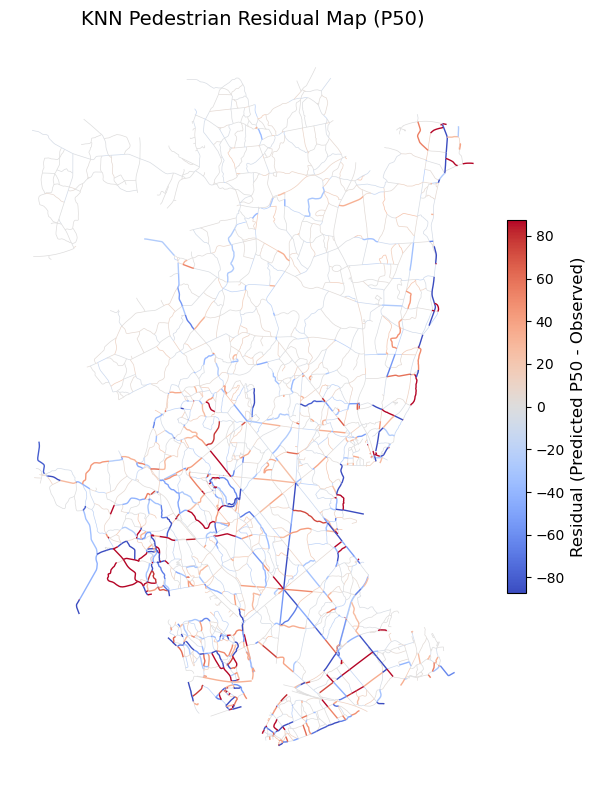

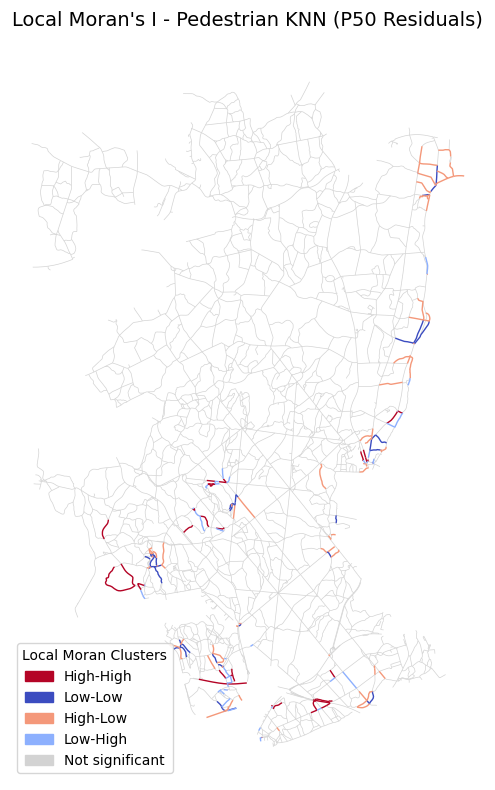

-> Plotting maps for RF ...


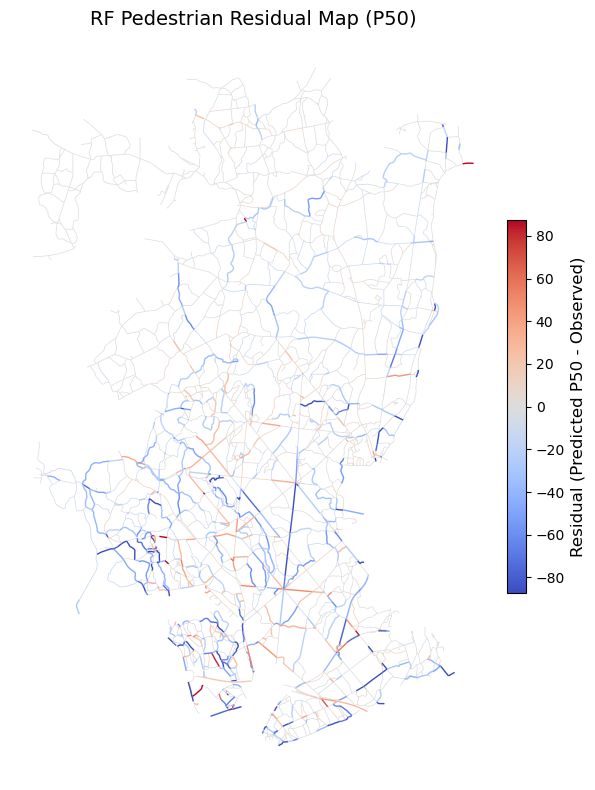

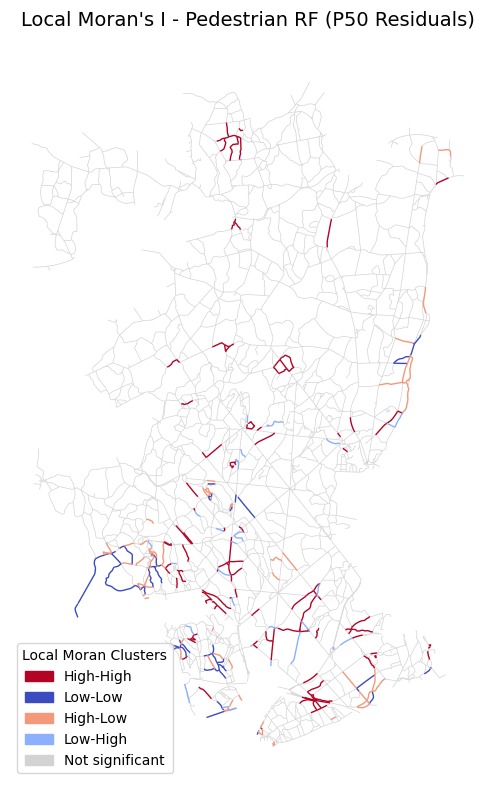

-> Plotting maps for XGB ...


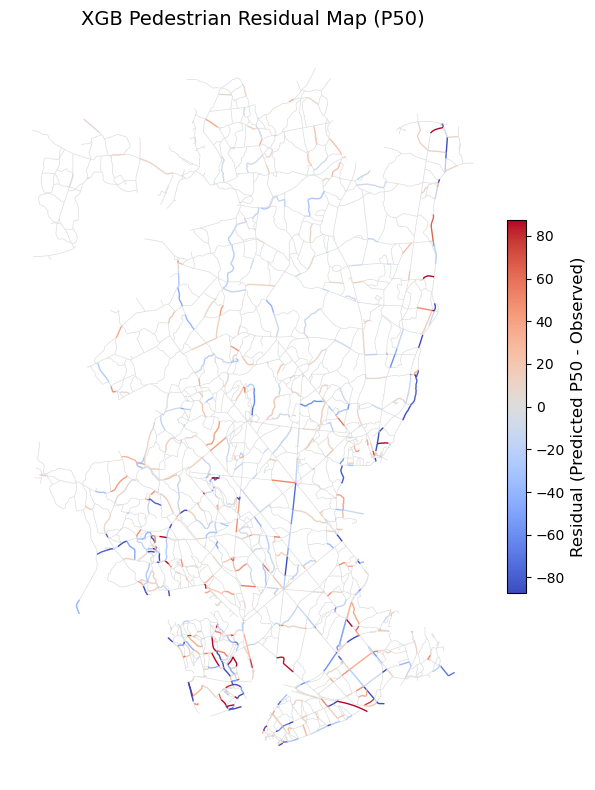

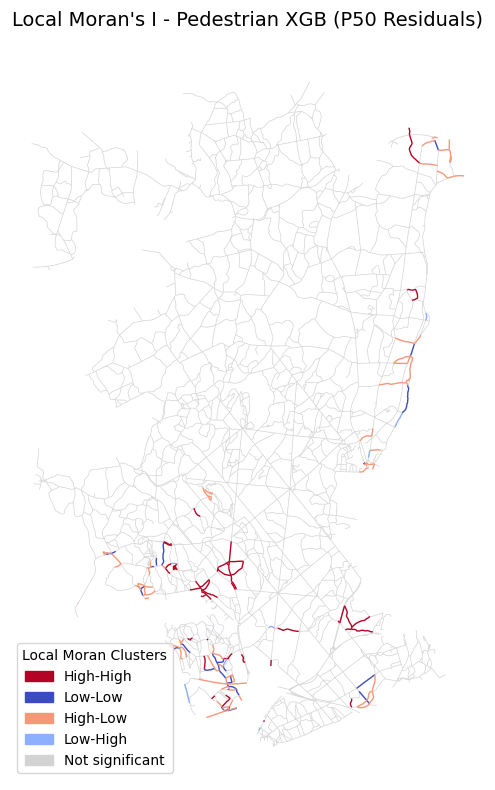

-> Plotting maps for LGB ...


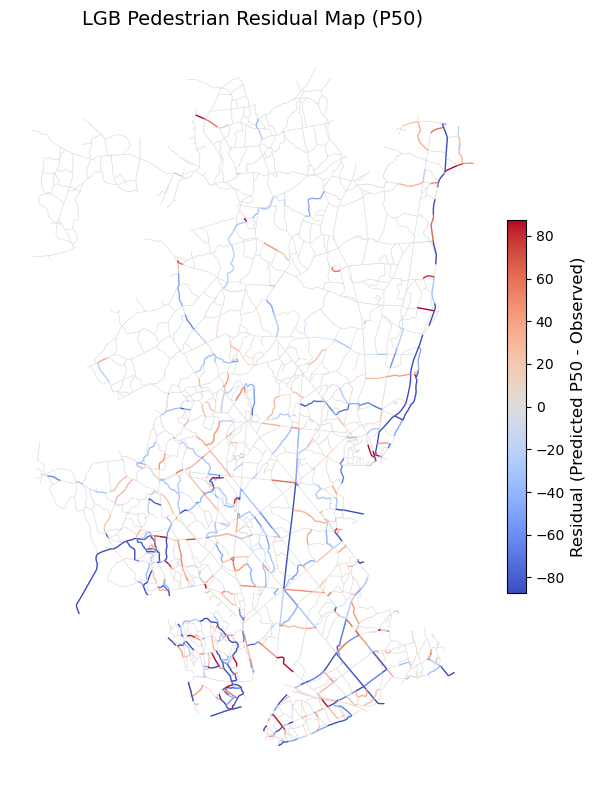

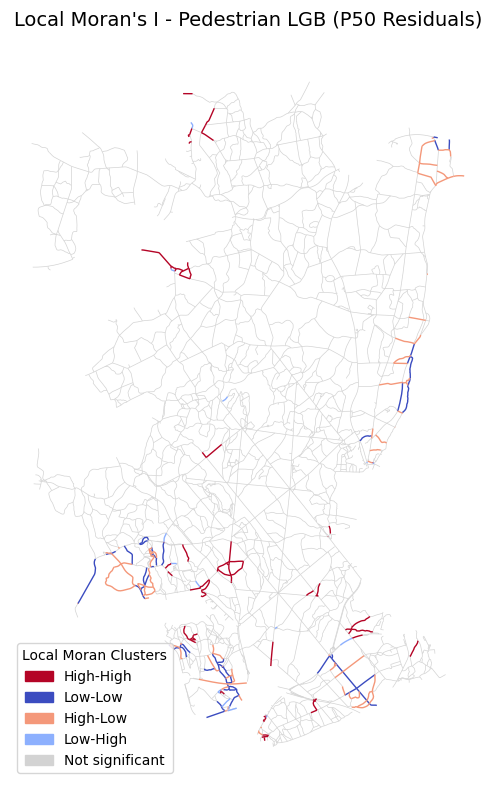

-> Plotting maps for GBRT ...


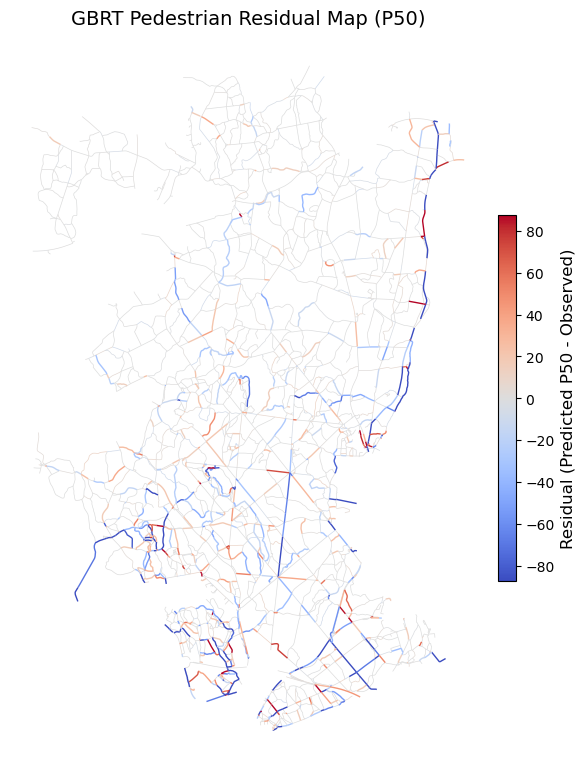

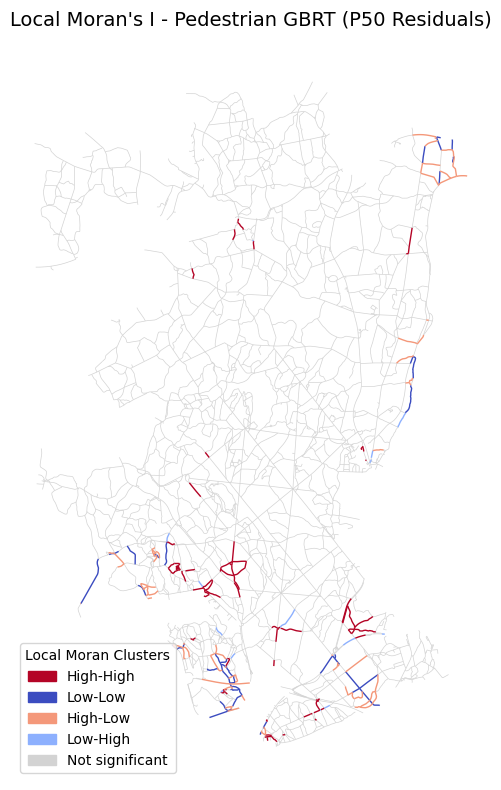

✅ All residual and Local Moran maps saved and displayed.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from libpysal.weights import KNN
from esda.moran import Moran_Local
from matplotlib.colors import to_hex


BASE_PATH = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/residual"
os.makedirs(BASE_PATH, exist_ok=True)


SCALER_PATH = "scaler_qr_ped.pkl"


MODEL_PATHS = {
    "KNN":  "knn_qr_ped.pkl",
    "RF":   "qrf_qr_ped.pkl",      # RandomForestQuantileRegressor（QRF）
    "XGB":  "xgb_qr_ped.pkl",      # dict {0.05, 0.5, 0.95}
    "LGB":  "lgb_qr_ped.pkl",      # dict {0.05, 0.5, 0.95}
    "GBRT": "gbrt_qr_ped.pkl",     # dict {0.05, 0.5, 0.95}
}


def get_p50_predictions(model_key, model, x_scaled):
    """
    返回 P50 预测：
    - RF(QRF): 直接分位预测 quantiles=0.5
    - KNN:     用 kneighbors 的 y 分布中位数作为 P50
    - 其它:    字典取 0.5 的模型
    """
    if model_key == "RF":
        
        return model.predict(x_scaled, quantiles=0.5)

    elif model_key == "KNN":
        
        _, neighbor_idx = model.kneighbors(x_scaled)
        y_train_used = np.asarray(model._y).reshape(-1)
        y_neighbors = y_train_used[neighbor_idx]
        return np.percentile(y_neighbors, 50, axis=1)

    else:
        
        return model[0.5].predict(x_scaled)

def plot_residual_map(gdf, residual_col, title, save_path, vmin, vmax):
    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = colormaps["coolwarm"]

    thr = np.percentile(np.abs(gdf[residual_col]), 75)
    gdf_thin  = gdf[np.abs(gdf[residual_col]) <= thr]
    gdf_thick = gdf[np.abs(gdf[residual_col]) >  thr]

    fig, ax = plt.subplots(figsize=(12, 8))
    gdf_thin.plot(column=residual_col, cmap=cmap, norm=norm, linewidth=0.5, ax=ax)
    gdf_thick.plot(column=residual_col, cmap=cmap, norm=norm, linewidth=1.0, ax=ax)

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm._A = []
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, orientation='vertical', pad=0.01)
    cbar.set_label("Residual (Predicted P50 - Observed)", fontsize=12)

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

def plot_local_moran(gdf, residual_col, title, save_path, k=12):
    gdf_proj = gdf.to_crs(epsg=25832) if gdf.crs is not None else gdf.copy()
    coords = np.array([(geom.centroid.x, geom.centroid.y) for geom in gdf_proj.geometry])

    w = KNN.from_array(coords, k=k)
    w.transform = 'r'
    moran_local = Moran_Local(gdf_proj[residual_col].to_numpy(), w)

    gdf_plot = gdf.copy()
    gdf_plot["local_p"] = moran_local.p_sim
    gdf_plot["sig"]     = gdf_plot["local_p"] < 0.05
    cluster_map = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
    lisa_labels = np.array(["Not significant"] * len(gdf_plot), dtype=object)
    sig_idx = gdf_plot["sig"].to_numpy()
    lisa_labels[sig_idx] = np.vectorize(cluster_map.get)(moran_local.q[sig_idx])
    gdf_plot["LISA_type"] = lisa_labels

    cmap = colormaps["coolwarm"]
    color_map = {
        "High-High": to_hex(cmap(1.0)),
        "Low-Low":   to_hex(cmap(0.0)),
        "High-Low":  to_hex(cmap(0.75)),
        "Low-High":  to_hex(cmap(0.25)),
        "Not significant": "#d3d3d3"
    }

    fig, ax = plt.subplots(figsize=(12, 8))
    gdf_plot[gdf_plot["LISA_type"] == "Not significant"].plot(
        ax=ax, color=color_map["Not significant"], linewidth=0.5, zorder=1
    )
    for cat in ["High-High", "Low-Low", "High-Low", "Low-High"]:
        gdf_plot[gdf_plot["LISA_type"] == cat].plot(
            ax=ax, color=color_map[cat], linewidth=1.0, zorder=2
        )

    legend_order = ["High-High", "Low-Low", "High-Low", "Low-High", "Not significant"]
    patches = [mpatches.Patch(color=color_map[k], label=k) for k in legend_order]
    ax.legend(handles=patches, title="Local Moran Clusters", loc='lower left')

    ax.set_title(title, fontsize=14)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

def run_all_models(dataset, selected_columns):
    scaler = joblib.load(SCALER_PATH)
    features = [c for c in selected_columns if c in dataset.columns]
    x_full = dataset[features]
    y_true_full = dataset['ped_avg'].to_numpy()
    x_full_scaled = scaler.transform(x_full)

    residual_map = {}
    gdfs = {}
    for key, path in MODEL_PATHS.items():
        print(f"-> Predicting P50 for {key} ...")
        model_obj = joblib.load(path)
        y_p50 = get_p50_predictions(key, model_obj, x_full_scaled)
        residual = y_p50 - y_true_full

        residual_col = f"residual_p50_{key}"
        gdf = gpd.GeoDataFrame(dataset.copy(), geometry='geometry')
        gdf[residual_col] = residual
        gdfs[key] = (gdf, residual_col)
        residual_map[key] = residual

    all_residuals = np.concatenate(list(residual_map.values()))
    limit = np.percentile(np.abs(all_residuals), 95)
    vmin, vmax = -limit, limit
    print(f"Unified color scale: vmin={vmin:.2f}, vmax={vmax:.2f}")

    for key, (gdf, residual_col) in gdfs.items():
        out_residual = os.path.join(BASE_PATH, f"{key}_residual_map_ped.png")
        out_moran    = os.path.join(BASE_PATH, f"{key}_residual_Moran_ped.png")

        print(f"-> Plotting maps for {key} ...")
        plot_residual_map(
            gdf, residual_col,
            title=f"{key} Pedestrian Residual Map (P50)",
            save_path=out_residual,
            vmin=vmin, vmax=vmax
        )
        plot_local_moran(
            gdf, residual_col,
            title=f"Local Moran's I - Pedestrian {key} (P50 Residuals)",
            save_path=out_moran,
            k=12
        )

run_all_models(dataset, selected_columns)


# Predicted results for new plan

According to the model performance, we choose **Gradient Boosting** method as the optimal model.

In [9]:
dataset_new = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/Joint feature/strava_roadnetwork_newplan.gpkg", layer = 'strava_roadnetwork_newplan')
dataset_network_changed = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/Joint feature/strava_roadnetwork_newplan_network.gpkg")
dataset_land_changed = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/Joint feature/strava_roadnetwork_newplan_land.gpkg")
dataset_reduced = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/Joint feature/strava_counts_feature_dataset_reduced.gpkg")

In [7]:
NNP_boundary = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/GribSkov_Polygons/GRIB_NNP_Indre_Hegn.shp")
Gates = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/New gates/Porte.shp")
deleted_entrance = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/new plan/deleted_entrance.shp")
wetland_new = gpd.read_file("/Users/wmv973/OneDrive - University of Copenhagen/Data storage/OriginalData/new plan/Hydro BIO 2018 NNP.gpkg")

c:\Users\wmv973\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


### Predicted Changes

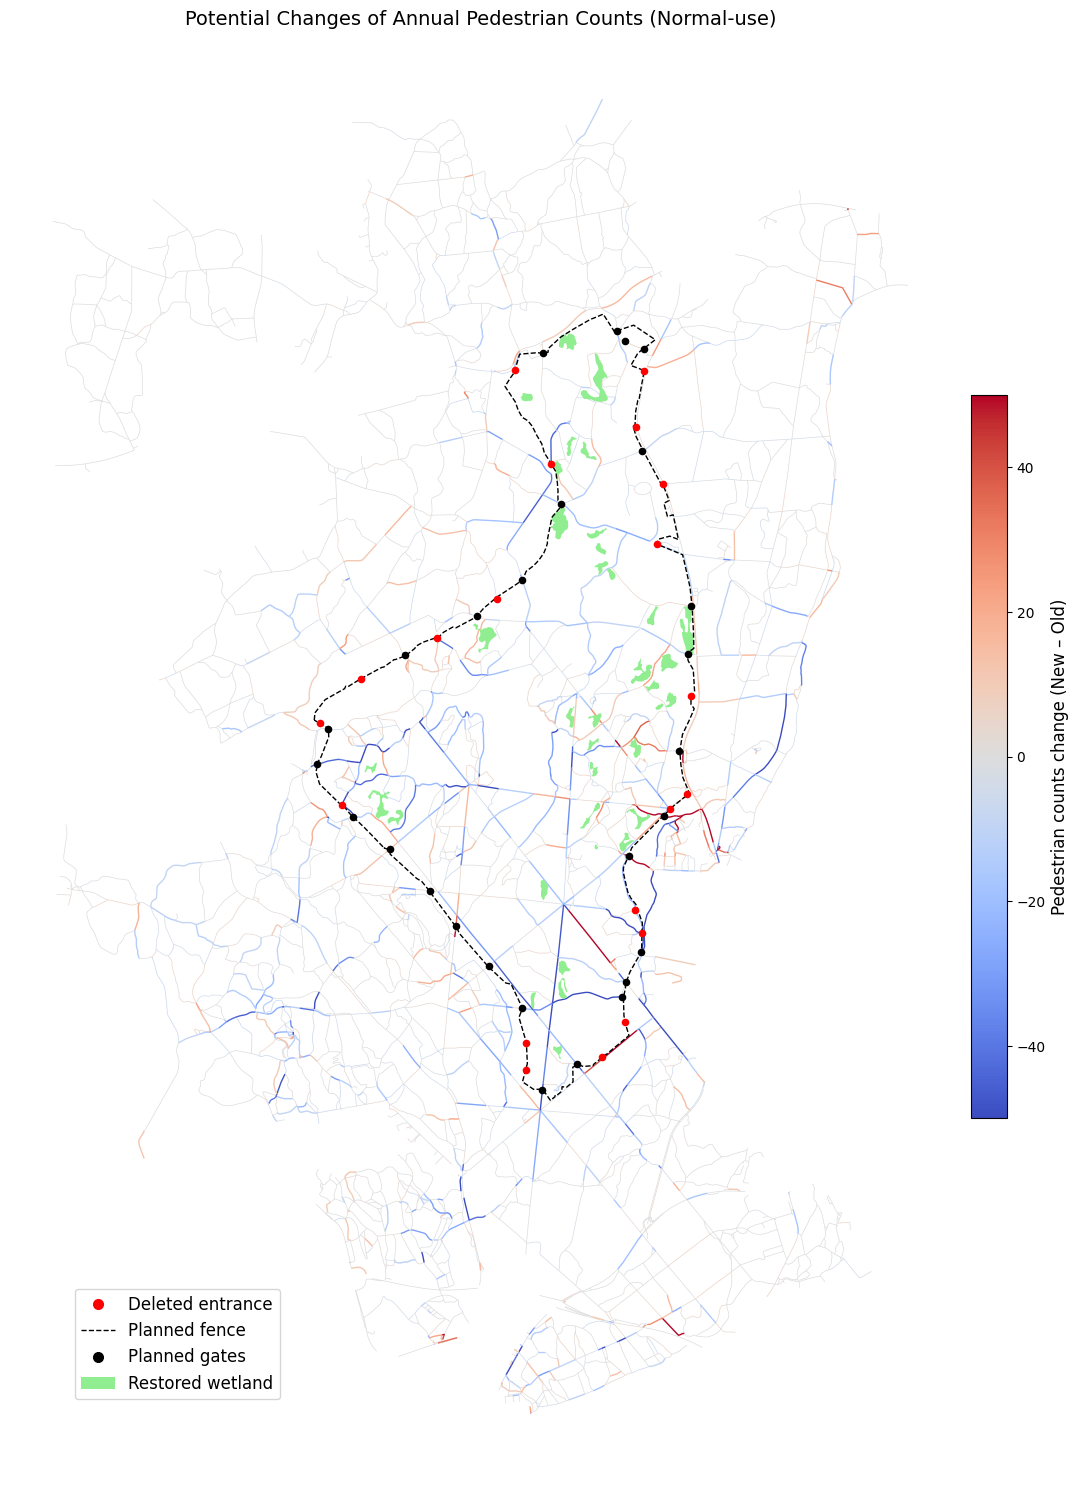

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib import colormaps
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


out_base = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes"

models = joblib.load("xgb_cqr_ped.pkl")
scaler = joblib.load("scaler_cqr_ped.pkl")
model_p50 = models[0.5]

selected_columns = [
    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
    'BtH2000',
    'MHD5000',
    '5_walk_route','2_run_route', '13_daisy_route',
    'width',
    'eDiff_500', 'avgSlope_500',
    'popula_1000m',
    'parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
]

feat = selected_columns
key = "edgeUID_24"

dataset[key] = dataset[key].astype(str)
dataset_new[key] = dataset_new[key].astype(str)

left  = gpd.GeoDataFrame(dataset_new[[key, "geometry"] + feat].copy(), geometry="geometry")
right = dataset[[key] + feat].copy()

merged = left.merge(right, on=key, how="inner", suffixes=("_new", "_old"))

X_new = merged[[f"{c}_new" for c in feat]].rename(columns=lambda s: s.replace("_new", ""))
X_old = merged[[f"{c}_old" for c in feat]].rename(columns=lambda s: s.replace("_old", ""))

X_new_s = scaler.transform(X_new)
X_old_s = scaler.transform(X_old)

pred_new_p50 = model_p50.predict(X_new_s)
pred_old_p50 = model_p50.predict(X_old_s)

change_abs = pred_new_p50 - pred_old_p50
gdf_abs = gpd.GeoDataFrame(merged[[key, "geometry"]].copy(), geometry="geometry")
gdf_abs["change_abs"] = change_abs

def plot_change_map(gdf, column, title, outfile, pct=False):
    vals = gdf[column].to_numpy()
    vmin, vmax = -50, 50
    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = colormaps["coolwarm"]

    thr = np.nanpercentile(np.abs(vals), 75)
    gdf_thin  = gdf[np.abs(gdf[column]) <= thr]
    gdf_thick = gdf[np.abs(gdf[column]) >  thr]

    fig, ax = plt.subplots(figsize=(20, 15))
    gdf_thin.plot (column=column, cmap=cmap, norm=norm, linewidth=0.5, ax=ax, zorder=1)
    gdf_thick.plot(column=column, cmap=cmap, norm=norm, linewidth=1.0, ax=ax, zorder=1)

    wetland_new.plot(ax=ax, color='lightgreen', zorder=2)
    NNP_boundary.plot(ax=ax, edgecolor='black', linestyle='--', linewidth=1, facecolor='none', zorder=3)
    Gates.plot(ax=ax, color='black', markersize=20, zorder=4)
    deleted_entrance.plot(ax=ax, color='red', markersize=20, zorder=5)

    handles = [
        Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='none',markersize=8, label='Deleted entrance'),
        Line2D([0], [0], color='black', linestyle='--', linewidth=1, label='Planned fence'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='none',markersize=8, label='Planned gates'),
        Patch(facecolor='lightgreen', edgecolor='none', label='Restored wetland')
    ]
    ax.legend(
        handles=handles,
        loc='lower left',
        bbox_to_anchor=(0.06, 0.05),
        frameon=True,
        fontsize=12
    )

    sm = ScalarMappable(norm=norm, cmap=cmap); sm._A = []
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, orientation='vertical', pad=0.01)
    cbar.set_label("Change (%)" if pct else "Pedestrian counts change (New – Old)", fontsize=12)

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()


plot_change_map(
    gdf_abs,
    column="change_abs",
    title="Potential Changes of Annual Pedestrian Counts (Normal-use)",
    outfile=f"{out_base}/XGB_change_abs_ped_p50_50.png",
    pct=False
)


### Predicted high-use change

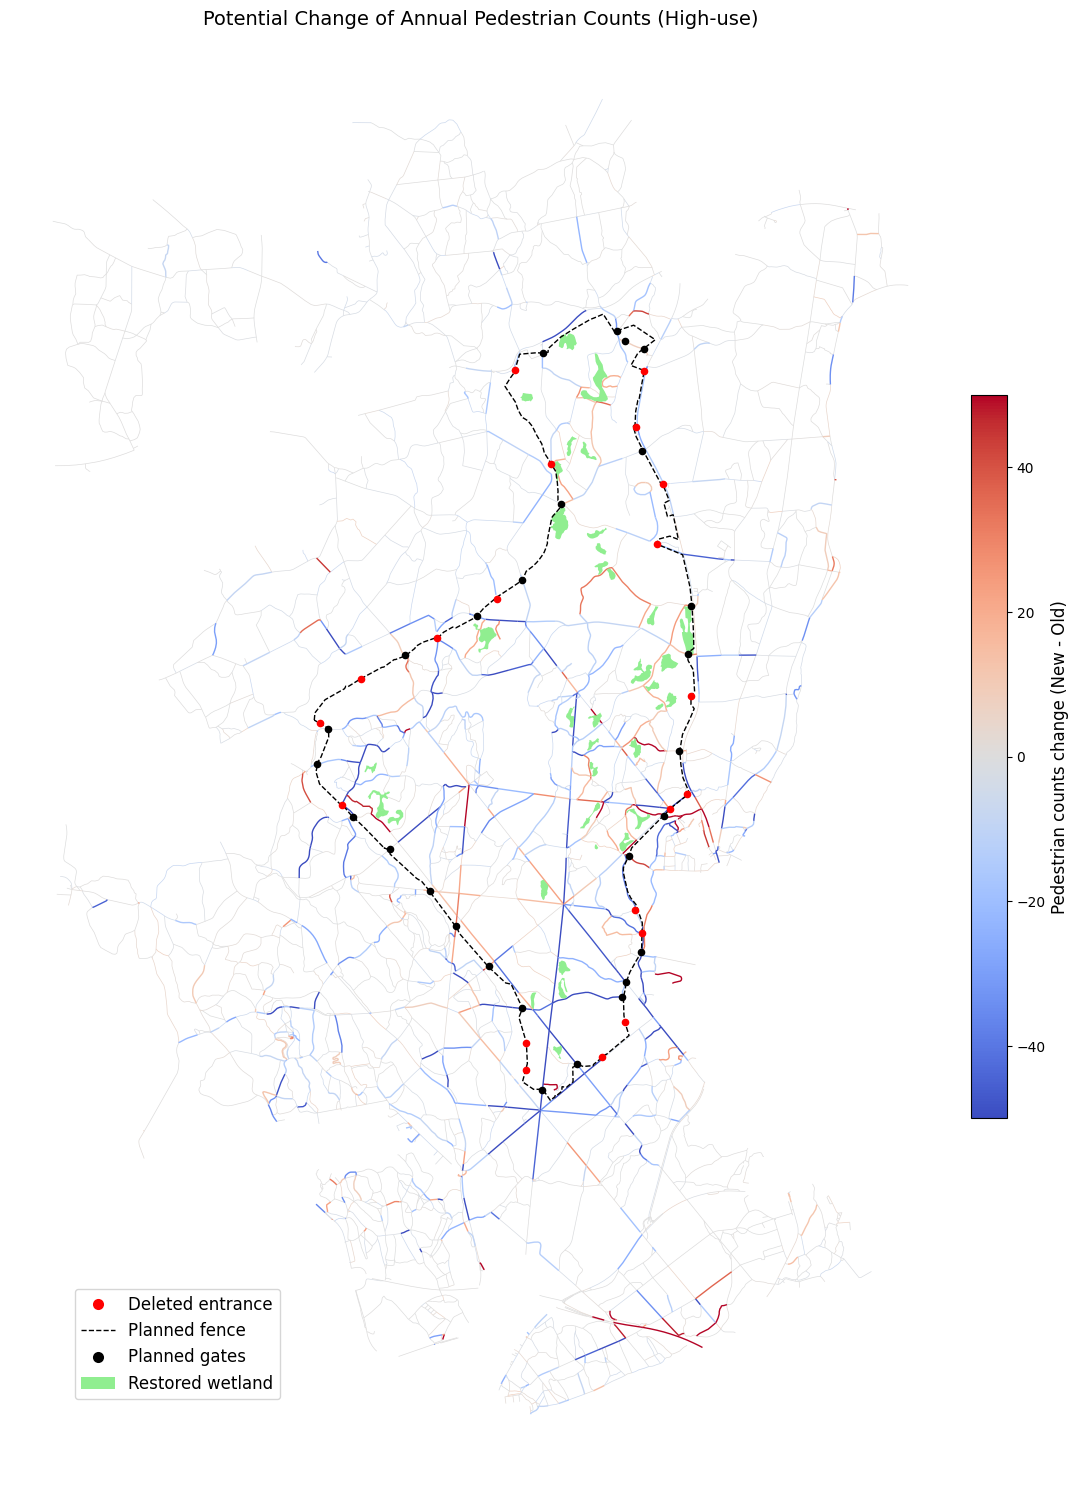

In [ ]:
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib import colormaps
import joblib


out_base = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes"


models = joblib.load("xgb_cqr_ped.pkl")      # dict: {0.05, 0.5, 0.95}
scaler = joblib.load("scaler_cqr_ped.pkl")
model_p95 = models[0.95]


qhats = joblib.load("cqr_calibration_qhats_XGBoost.pkl") 
q_hat = float(qhats["q_hat_90"])


selected_columns = [
    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
    'BtH2000',
    'MHD5000',
    '5_walk_route','2_run_route', '13_daisy_route', 
    'width',
    'eDiff_500', 'avgSlope_500',
    'popula_1000m',
    'parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
]
feat = selected_columns
key = "edgeUID_24"


dataset[key] = dataset[key].astype(str)
dataset_new[key] = dataset_new[key].astype(str)

left  = gpd.GeoDataFrame(dataset_new[[key, "geometry"] + feat].copy(), geometry="geometry")
right = dataset[[key] + feat].copy()

merged = left.merge(right, on=key, how="inner", suffixes=("_new", "_old"))

X_new = merged[[f"{c}_new" for c in feat]].rename(columns=lambda s: s.replace("_new", ""))
X_old = merged[[f"{c}_old" for c in feat]].rename(columns=lambda s: s.replace("_old", ""))

X_new_s = scaler.transform(X_new)
X_old_s = scaler.transform(X_old)

p95_new_base = model_p95.predict(X_new_s)
p95_old_base = model_p95.predict(X_old_s)

pred_new_p95 = p95_new_base + q_hat
pred_old_p95 = p95_old_base + q_hat

delta_p95 = pred_new_p95 - pred_old_p95


gdf = gpd.GeoDataFrame(merged[[key, "geometry"]].copy(), geometry="geometry")
gdf["delta_p95"] = delta_p95


def plot_change_map(gdf, column, title, outfile):
    vals = gdf[column].to_numpy()
    vlim = np.nanpercentile(np.abs(vals), 95)
    
    vmin, vmax = -50, 50
    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = colormaps["coolwarm"]

    thr = np.nanpercentile(np.abs(vals), 75)
    gdf_thin  = gdf[np.abs(vals) <= thr]
    gdf_thick = gdf[np.abs(vals) >  thr]

    fig, ax = plt.subplots(figsize=(20, 15))
    if not gdf_thin.empty:
        gdf_thin.plot (column=column, cmap=cmap, norm=norm, linewidth=0.5, ax=ax)
    if not gdf_thick.empty:
        gdf_thick.plot(column=column, cmap=cmap, norm=norm, linewidth=1.0, ax=ax)
    

    wetland_new.plot(ax=ax, color='lightgreen', zorder=2)
    NNP_boundary.plot(ax=ax, edgecolor='black', linestyle='--', linewidth=1, facecolor='none', zorder=3)
    Gates.plot(ax=ax, color='black', markersize=20, zorder=4)
    deleted_entrance.plot(ax=ax, color='red', markersize=20, zorder=5)

    
    handles = [
        Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='none',markersize=8, label='Deleted entrance'),
        Line2D([0], [0], color='black', linestyle='--', linewidth=1, label='Planned fence'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='none',markersize=8, label='Planned gates'),
        Patch(facecolor='lightgreen', edgecolor='none', label='Restored wetland')
    ]
    ax.legend(
        handles=handles,
        loc='lower left',
        bbox_to_anchor=(0.06, 0.05),
        frameon=True,
        fontsize=12
    )
    
    sm = ScalarMappable(norm=norm, cmap=cmap); sm._A = []
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, pad=0.01)
    cbar.set_label(f"Pedestrian counts change (New - Old)", fontsize=12)

    ax.set_title(title, fontsize=14)
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()

plot_change_map(
    gdf, "delta_p95",
    title="Potential Change of Annual Pedestrian Counts (High-use)",
    outfile=f"{out_base}/XGBoost_change_P95_ped_50.png"
)

### Predicted trails with reliable and obvious changes

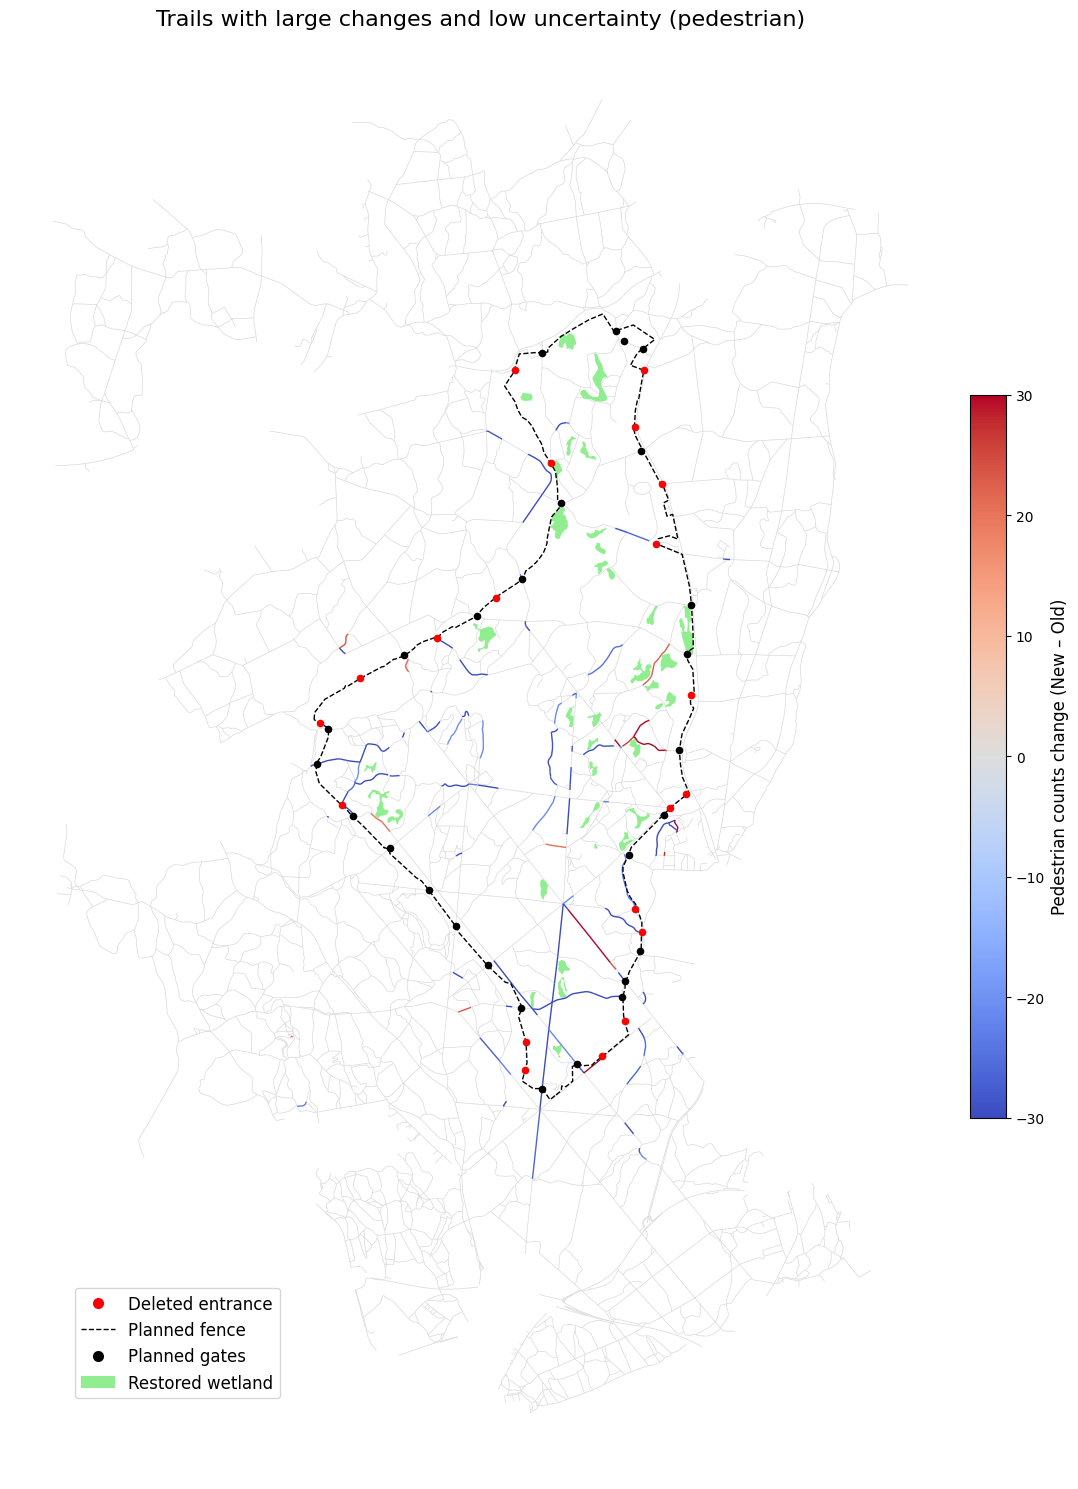

Saved: /Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes/XGB_ped_change_filtered_30.png


In [34]:
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib import colormaps


xgb_models = joblib.load("xgb_cqr_ped.pkl")         # dict: {0.05: model, 0.5: model, 0.95: model, ...}
scaler     = joblib.load("scaler_cqr_ped.pkl")
qhats      = joblib.load("cqr_calibration_qhats_XGBoost.pkl")  # {"q_hat_80":..., "q_hat_90":...}
q_hat_90   = float(qhats.get("q_hat_90", list(qhats.values())[0]))


selected_columns = [
    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
    'BtH2000',
    'MHD5000',
    '5_walk_route','2_run_route', '13_daisy_route', 
    'width',
    'eDiff_500', 'avgSlope_500',
    'popula_1000m',
    'parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
]

features = [c for c in selected_columns if (c in dataset_new.columns) and (c in dataset.columns)]


key_col = "edgeUID_24"   


dataset_new[key_col] = dataset_new[key_col].astype(str)
dataset[key_col]     = dataset[key_col].astype(str)


left  = gpd.GeoDataFrame(dataset_new[[key_col, "geometry"] + features].copy(), geometry="geometry")
right = dataset[[key_col] + features].copy()
merged_feat = left.merge(right, on=key_col, how="inner", suffixes=("_new", "_old"))


X_new = merged_feat[[f"{c}_new" for c in features]].rename(columns=lambda s: s.replace("_new", ""))
X_old = merged_feat[[f"{c}_old" for c in features]].rename(columns=lambda s: s.replace("_old", ""))

X_new_s = scaler.transform(X_new)
X_old_s = scaler.transform(X_old)


p05_new = xgb_models[0.05].predict(X_new_s)
p95_new = xgb_models[0.95].predict(X_new_s)

p05_old = xgb_models[0.05].predict(X_old_s)
p95_old = xgb_models[0.95].predict(X_old_s)


p05_new_c = np.maximum(p05_new - q_hat_90, 0.0)
p95_new_c = p95_new + q_hat_90
width_new = p95_new_c - p05_new_c

p05_old_c = np.maximum(p05_old - q_hat_90, 0.0)
p95_old_c = p95_old + q_hat_90
width_old = p95_old_c - p05_old_c


inter = np.maximum(0.0, np.minimum(p95_new_c, p95_old_c) - np.maximum(p05_new_c, p05_old_c))
union = np.maximum(1e-12, np.maximum(p95_new_c, p95_old_c) - np.minimum(p05_new_c, p05_old_c))
overlap_ratio = inter / union  # IoU in [0,1]

gdf_width = gpd.GeoDataFrame(
    merged_feat[[key_col, "geometry"]].copy(),
    geometry="geometry"
)
gdf_width["width_cqr"]      = width_new
gdf_width["overlap_ratio"]  = overlap_ratio


p50_new = xgb_models[0.50].predict(X_new_s)
p50_old = xgb_models[0.50].predict(X_old_s)

gdf_abs = gpd.GeoDataFrame(
    merged_feat[[key_col, "geometry"]].copy(),
    geometry="geometry"
)
gdf_abs["change_abs"] = (p50_new - p50_old) 


gdf_abs[key_col]   = gdf_abs[key_col].astype(str)
gdf_width[key_col] = gdf_width[key_col].astype(str)

gdf_merged = gdf_abs[[key_col, "geometry", "change_abs"]].merge(
    gdf_width[[key_col, "width_cqr", "overlap_ratio"]],
    on=key_col,
    how="inner"
)

gdf_merged["abs_change"] = gdf_merged["change_abs"].abs()


mask_target = (
    (gdf_merged["abs_change"] >= 20) &
    (gdf_merged["width_cqr"] < 200) &
    (gdf_merged["overlap_ratio"] <= 0.90)
)
gdf_target = gdf_merged[mask_target].copy()
gdf_other  = gdf_merged[~mask_target].copy()


def plot_change_with_uncertainty(
    gdf_target, gdf_other,
    title,
    outfile
):
    if len(gdf_target) == 0:
        print("no trail meet requirement")
        return

    vals = gdf_target["change_abs"].to_numpy()

    vlim = 30.0
    vmin, vmax = -vlim, vlim
    norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
    cmap = colormaps["coolwarm"]

    fig, ax = plt.subplots(figsize=(20, 15))

    if len(gdf_other) > 0:
        gdf_other.plot(ax=ax, color="#d9d9d9", linewidth=0.5, zorder=1)

   
    gdf_target.plot(
        column="change_abs",
        cmap=cmap,
        norm=norm,
        linewidth=1.0,   
        ax=ax,
        zorder=3
    )

    wetland_new.plot(ax=ax, color='lightgreen', zorder=2)
    NNP_boundary.plot(ax=ax, edgecolor='black', linestyle='--', linewidth=1, facecolor='none', zorder=3)
    Gates.plot(ax=ax, color='black', markersize=20, zorder=4)
    deleted_entrance.plot(ax=ax, color='red', markersize=20, zorder=5)


    handles = [
        Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='none',markersize=8, label='Deleted entrance'),
        Line2D([0], [0], color='black', linestyle='--', linewidth=1, label='Planned fence'),
        Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='none',markersize=8, label='Planned gates'),
        Patch(facecolor='lightgreen', edgecolor='none', label='Restored wetland')
    ]
    ax.legend(
        handles=handles,
        loc='lower left',
        bbox_to_anchor=(0.06, 0.05),
        frameon=True,
        fontsize=12
    )

    sm = ScalarMappable(norm=norm, cmap=cmap); sm._A = []
    cbar = fig.colorbar(sm, ax=ax, shrink=0.5, orientation='vertical', pad=0.01)
    cbar.set_label("Pedestrian counts change (New – Old)", fontsize=12)

    ax.set_title(title, fontsize=16)
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(outfile, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {outfile}")

out_base = "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes"
out_file = f"{out_base}/XGB_ped_change_filtered_30.png"

plot_change_with_uncertainty(
    gdf_target,
    gdf_other,
    # title="Pedestrian: |ΔP50| ≥ 20 & 90% interval width < 200 & interval overlap ≤ 90%",
    title= "Trails with large changes and low uncertainty (pedestrian)",
    outfile=out_file
)


### Predicted change of the influence of single variables (land cover/network)

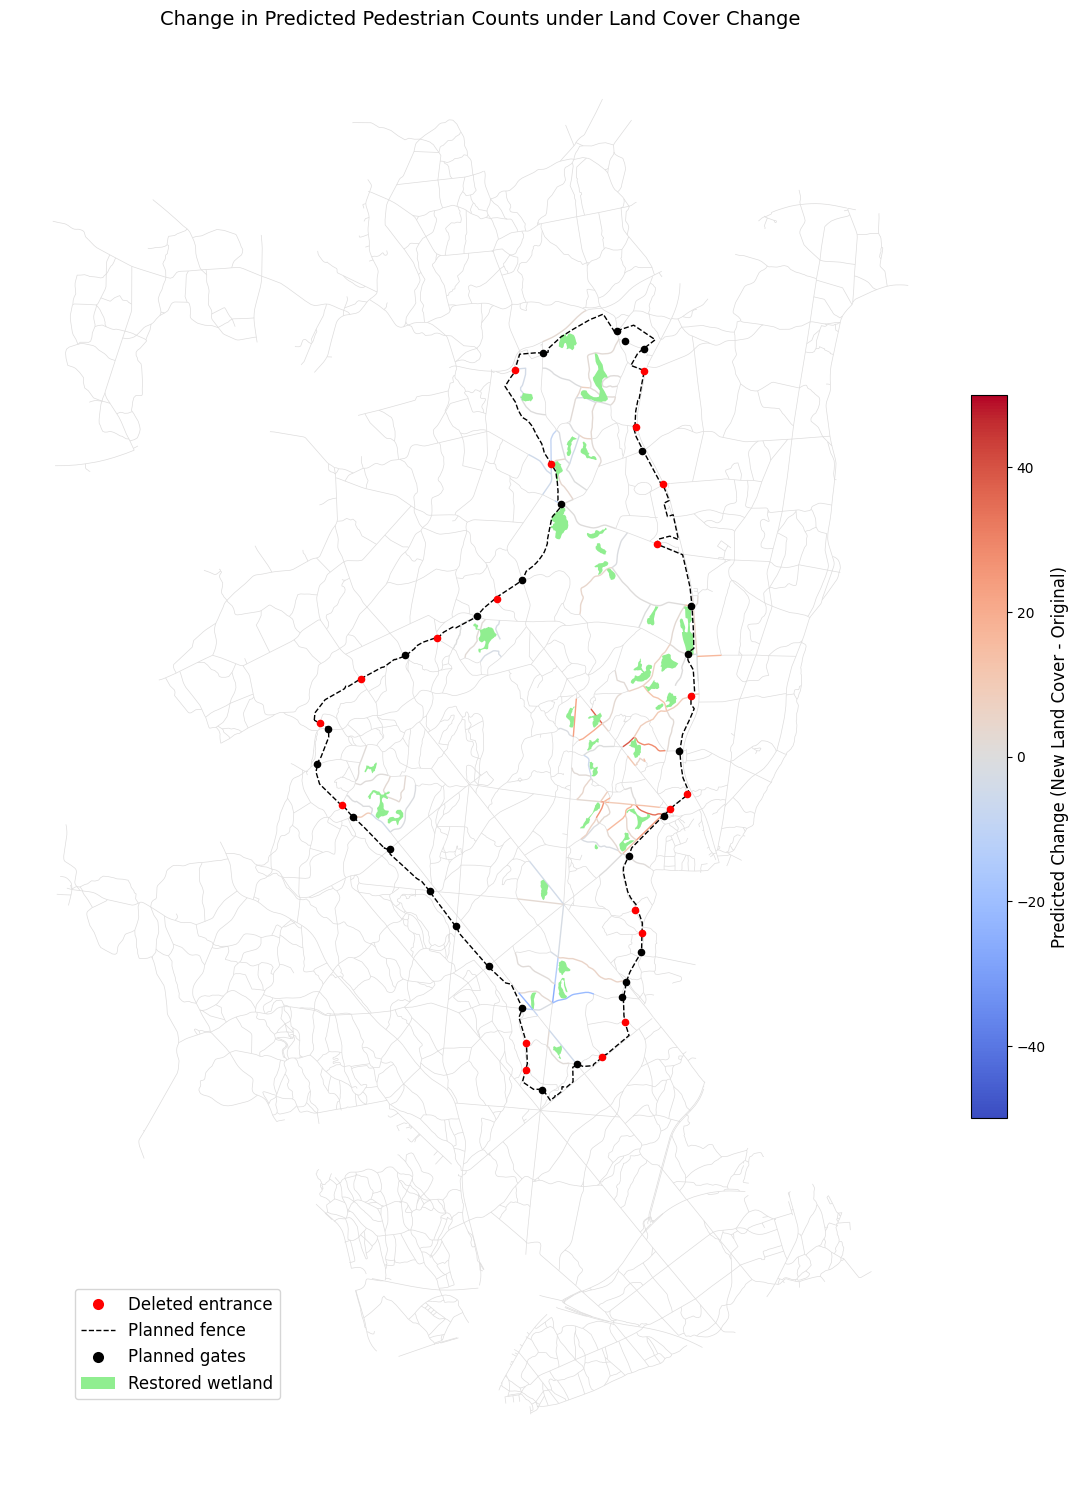

In [ ]:

models = joblib.load("xgb_cqr_ped.pkl")
scaler = joblib.load("scaler_cqr_ped.pkl")
model_median = models[0.5]


selected_columns = [
    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
    'BtH2000', 'MHD5000',
    '5_walk_route', '2_run_route', '13_daisy_route', 
    'width', 'eDiff_500', 'avgSlope_500',
    'popula_1000m', 'parking_2000m', 'train_station_2000m',
    'treecoverden_1000m', 'tree_age_500m',
    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns and c in dataset_land_changed.columns]

X_old = dataset[features]
X_new = dataset_land_changed[features]

X_old_scaled = scaler.transform(X_old)
X_new_scaled = scaler.transform(X_new)

y_old = model_median.predict(X_old_scaled)   
y_new = model_median.predict(X_new_scaled)   

gdf_change = gpd.GeoDataFrame(dataset.copy(), geometry='geometry')
gdf_change['predicted_original'] = y_old
gdf_change['predicted_new'] = y_new
gdf_change['change'] = gdf_change['predicted_new'] - gdf_change['predicted_original']


# vlim = gdf_change['change'].abs().max()
# vmin, vmax = -vlim, vlim
vmin, vmax = -50, 50
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = colormaps['coolwarm']

threshold = np.percentile(np.abs(gdf_change['change']), 75)
gdf_thin = gdf_change[np.abs(gdf_change['change']) <= threshold]
gdf_thick = gdf_change[np.abs(gdf_change['change']) > threshold]


fig, ax = plt.subplots(figsize=(20, 15))
gdf_thin.plot(column='change', cmap=cmap, norm=norm, linewidth=0.5, ax=ax)
gdf_thick.plot(column='change', cmap=cmap, norm=norm, linewidth=1.0, ax=ax)


wetland_new.plot(ax=ax, color='lightgreen', zorder=2)
NNP_boundary.plot(ax=ax, edgecolor='black', linestyle='--', linewidth=1, facecolor='none', zorder=3)
Gates.plot(ax=ax, color='black', markersize=20, zorder=4)
deleted_entrance.plot(ax=ax, color='red', markersize=20, zorder=5)


handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='none',markersize=8, label='Deleted entrance'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=1, label='Planned fence'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='none',markersize=8, label='Planned gates'),
    Patch(facecolor='lightgreen', edgecolor='none', label='Restored wetland')
]
ax.legend(
    handles=handles,
    loc='lower left',
    bbox_to_anchor=(0.06, 0.05),
    frameon=True,
    fontsize=12
)


sm = ScalarMappable(norm=norm, cmap=cmap)
sm._A = []
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, orientation='vertical', pad=0.01)
cbar.set_label("Predicted Change (New Land Cover - Original)", fontsize=12)

ax.set_title("Change in Predicted Pedestrian Counts under Land Cover Change", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes/XGBoost_change_ped_landcover_50.png",
    dpi=300, bbox_inches='tight'
)
plt.show()

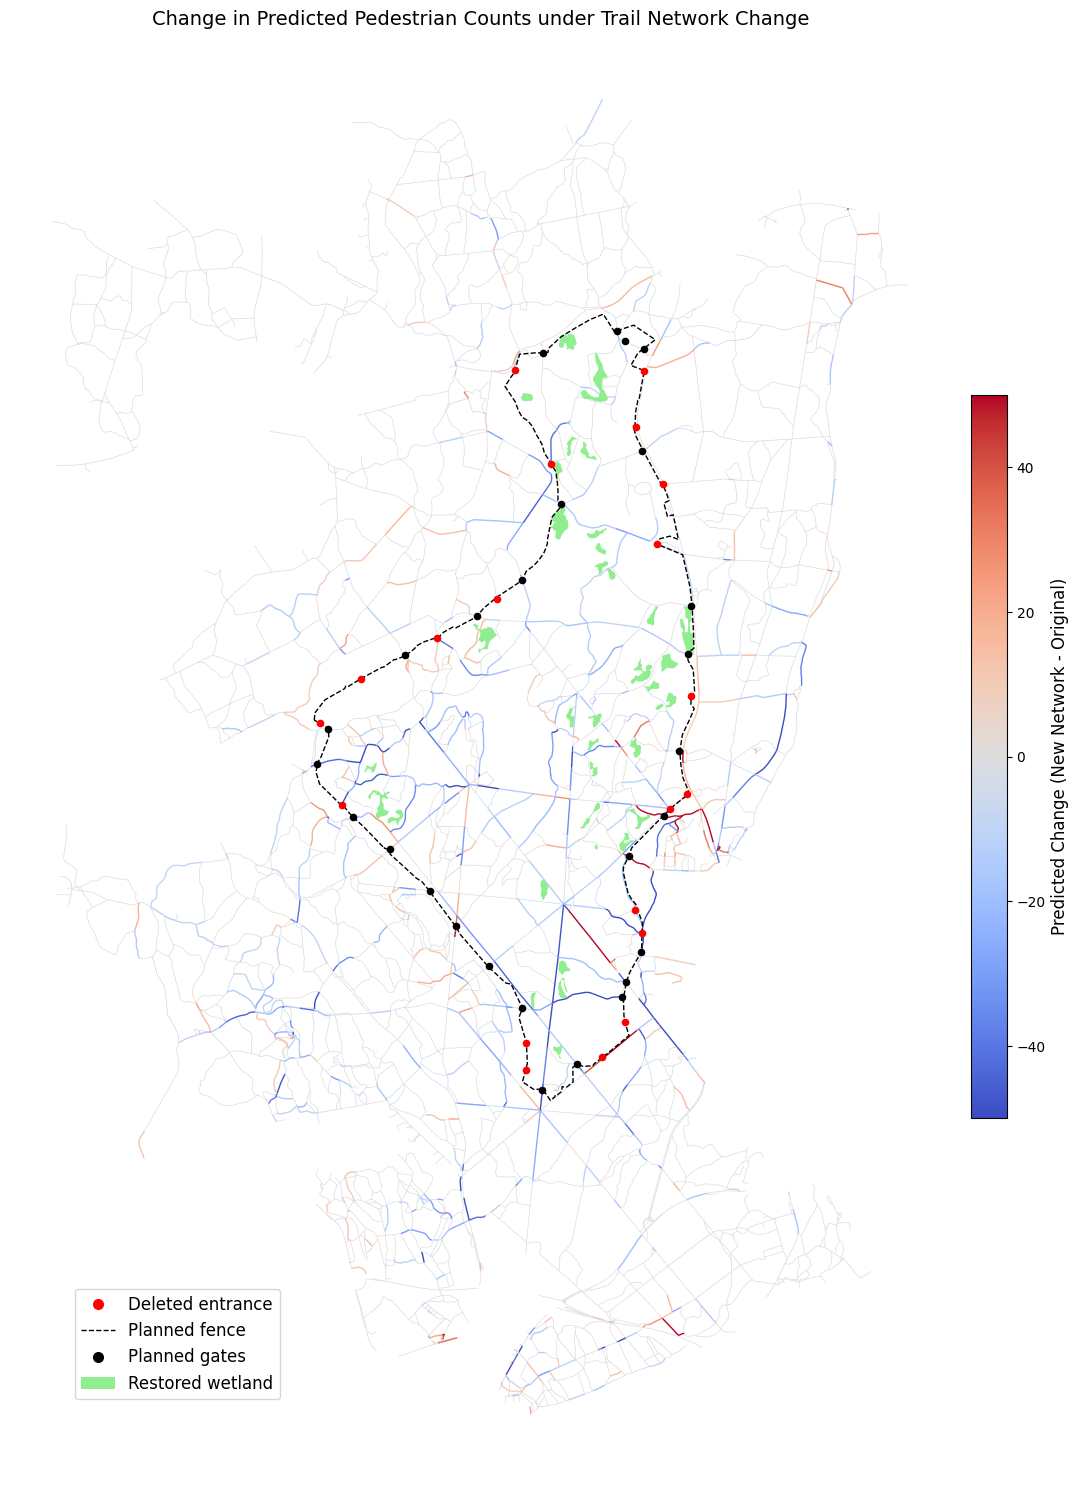

In [ ]:
models = joblib.load("xgb_cqr_ped.pkl")
scaler = joblib.load("scaler_cqr_ped.pkl")
model_median = models[0.5]

selected_columns = [
    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
    'BtH2000', 'MHD5000',
    '5_walk_route', '2_run_route', '13_daisy_route', 
    'width', 'eDiff_500', 'avgSlope_500',
    'popula_1000m', 'parking_2000m', 'train_station_2000m',
    'treecoverden_1000m', 'tree_age_500m',
    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
]

features = [c for c in selected_columns if c in dataset_reduced.columns and c in dataset_network_changed.columns]
if not features:
    raise ValueError("features 为空，请检查 selected_columns 与两个数据集的列名。")

X_old = dataset_reduced[features]
X_new = dataset_network_changed[features]

X_old_scaled = scaler.transform(X_old)
X_new_scaled = scaler.transform(X_new)

y_old = model_median.predict(X_old_scaled)   
y_new = model_median.predict(X_new_scaled)   

gdf_change = gpd.GeoDataFrame(dataset_reduced.copy(), geometry='geometry')
gdf_change['predicted_original'] = y_old
gdf_change['predicted_new'] = y_new
gdf_change['change'] = gdf_change['predicted_new'] - gdf_change['predicted_original']


# vlim = gdf_change['change'].abs().max()
# vmin, vmax = -vlim, vlim
vmin, vmax = -50, 50
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = colormaps['coolwarm']

threshold = np.percentile(np.abs(gdf_change['change']), 75)
gdf_thin = gdf_change[np.abs(gdf_change['change']) <= threshold]
gdf_thick = gdf_change[np.abs(gdf_change['change']) > threshold]

fig, ax = plt.subplots(figsize=(20, 15))
gdf_thin.plot(column='change', cmap=cmap, norm=norm, linewidth=0.5, ax=ax)
gdf_thick.plot(column='change', cmap=cmap, norm=norm, linewidth=1.0, ax=ax)


wetland_new.plot(ax=ax, color='lightgreen', zorder=2)
NNP_boundary.plot(ax=ax, edgecolor='black', linestyle='--', linewidth=1, facecolor='none', zorder=3)
Gates.plot(ax=ax, color='black', markersize=20, zorder=4)
deleted_entrance.plot(ax=ax, color='red', markersize=20, zorder=5)


handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='red', markeredgecolor='none',markersize=8, label='Deleted entrance'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=1, label='Planned fence'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='black', markeredgecolor='none',markersize=8, label='Planned gates'),
    Patch(facecolor='lightgreen', edgecolor='none', label='Restored wetland')
]
ax.legend(
    handles=handles,
    loc='lower left',
    bbox_to_anchor=(0.06, 0.05),
    frameon=True,
    fontsize=12
)


sm = ScalarMappable(norm=norm, cmap=cmap)
sm._A = []
cbar = fig.colorbar(sm, ax=ax, shrink=0.5, orientation='vertical', pad=0.01)
cbar.set_label("Predicted Change (New Network - Original)", fontsize=12)

ax.set_title("Change in Predicted Pedestrian Counts under Trail Network Change", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/changes/XGBoost_change_ped_network_50.png",
    dpi=300, bbox_inches='tight'
)
plt.show()

# Feature importance analysis

In [37]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import joblib

selected_columns = [
                    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
                    'BtH2000',
                    'MHD5000',
                    '5_walk_route','2_run_route', '13_daisy_route', 
                    'width',
                    'eDiff_500', 'avgSlope_500',
                    'popula_1000m',
                    'parking_2000m','train_station_2000m',
                    'treecoverden_1000m','tree_age_500m',
                    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
                   ]

features = [col for col in selected_columns if col in dataset.columns]

x = dataset[features]
y = dataset['ped_avg']

x_remain, x_test, y_remain, y_test = train_test_split(
    x, y, test_size=0.15, random_state=40
)
joblib.dump(y_test.index, "test_indices_ped_mean.pkl")

cal_rel = 0.15 / 0.85
x_train, x_cal, y_train, y_cal = train_test_split(
    x_remain, y_remain, test_size=cal_rel, random_state=40
)
joblib.dump(y_cal.index, "cal_indices_ped_mean.pkl")

test_indices = x_test.index

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


rf_regressor = RandomForestRegressor(n_estimators=300, max_depth=10, min_samples_split=5, min_samples_leaf= 2, random_state=42)  
rf_regressor.fit(x_train_scaled, y_train)

joblib.dump(rf_regressor, "random_forest_ped_mean.pkl")
joblib.dump(scaler, "scaler.pkl")


y_pred = rf_regressor.predict(x_test_scaled)


mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"R2 Score: {r2:.2f}")

Mean Squared Error (MSE): 10472.66
Mean Absolute Error (MAE): 46.57
R2 Score: 0.66


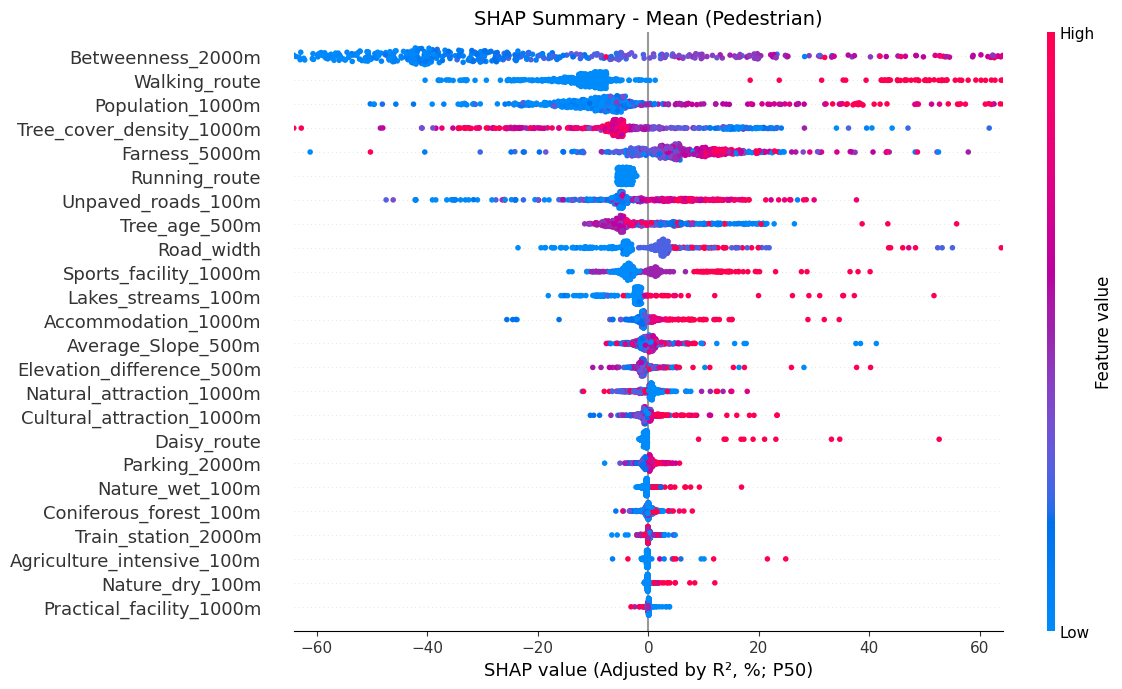

                       Feature  SHAP Importance  Normalized Importance (%)  \
6            Betweenness_2000m        46.052301                  29.133099   
8                Walking_route        21.448730                  13.568659   
14            Population_1000m        15.855696                  10.030456   
17    Tree_cover_density_1000m        13.319472                   8.426017   
7                Farness_5000m         9.521579                   6.023436   
9                Running_route         8.776087                   5.551832   
0           Unpaved_roads_100m         8.383333                   5.303372   
18               Tree_age_500m         6.441866                   4.075182   
11                  Road_width         5.903083                   3.734343   
22       Sports_facility_1000m         4.504197                   2.849396   
5           Lakes_streams_100m         4.211820                   2.664435   
21         Accommodation_1000m         2.142923                 

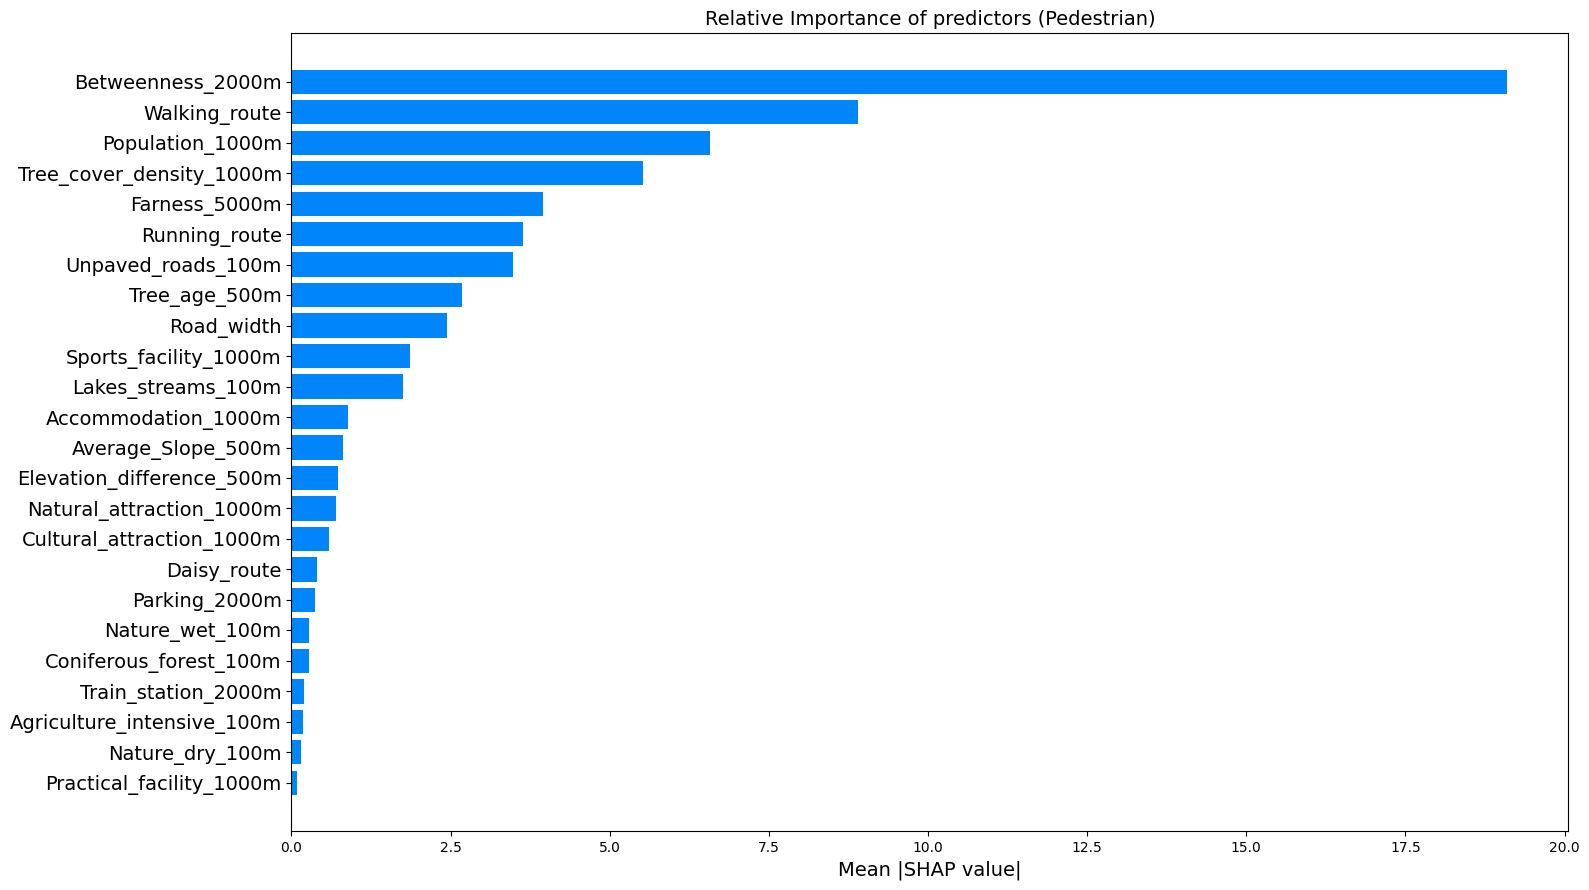

In [38]:
import shap

selected_columns = [
                    'BM_104_100', 'BM_201_100', 'BM_302_100', 'BM_401_100', 'BM_402_100', 'BM_501_100',
                    'BtH2000',
                    'MHD5000',
                    '5_walk_route','2_run_route', '13_daisy_route', 
                    'width',
                    'eDiff_500', 'avgSlope_500',
                    'popula_1000m',
                    'parking_2000m','train_station_2000m',
                    'treecoverden_1000m','tree_age_500m',
                    '5_culture_1000m', '2_natural_1000m', '3_accommodation_1000m', '4_sports_1000m', '1_practical_1000m'
                   ]

display_columns = ['Unpaved_roads_100m', 'Agriculture_intensive_100m', 'Coniferous_forest_100m', 'Nature_dry_100m', 'Nature_wet_100m', 'Lakes_streams_100m',
                    'Betweenness_2000m', 
                    'Farness_5000m',
                    'Walking_route', 'Running_route', 'Daisy_route',
                    'Road_width',
                    'Elevation_difference_500m', 'Average_Slope_500m',
                    'Population_1000m',
                    'Parking_2000m', 'Train_station_2000m',
                    'Tree_cover_density_1000m', 'Tree_age_500m',
                    'Practical_facility_1000m', 'Natural_attraction_1000m', 'Accommodation_1000m', 'Sports_facility_1000m', 'Cultural_attraction_1000m'
                    ]

features = display_columns 

model_explained_variance = r2

rf_regressor = joblib.load("random_forest_ped_mean.pkl")

explainer = shap.TreeExplainer(rf_regressor)

shap_values = explainer.shap_values(x_test_scaled)

shap.summary_plot(shap_values, x_test_scaled, feature_names=features, plot_size=(12, 7), max_display=len(features), show=False)

plt.xlabel("SHAP value (Adjusted by R², %; P50)", fontsize=13)

lim = np.percentile(np.abs(shap_values), 99)
if not np.isfinite(lim) or lim <= 0:
    lim = 1e-6
plt.xlim(-lim, lim)

plt.title("SHAP Summary - Mean (Pedestrian)", fontsize=14)
plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/feature selection/SHAP_beeswarm_ped_rf_mean_1.png",
    dpi=300, bbox_inches='tight'
)
plt.show()

sample_idx = np.random.randint(0, x_test_scaled.shape[0])
shap.force_plot(
    explainer.expected_value,
    shap_values[sample_idx],
    x_test_scaled[sample_idx],
    feature_names=features
)

feature_importance = np.abs(shap_values).mean(axis=0)
normalized_importance = feature_importance / feature_importance.sum() * 100
adjusted_importance = normalized_importance * model_explained_variance

importance_df = pd.DataFrame({
    'Feature': features,
    'SHAP Importance': feature_importance,
    'Normalized Importance (%)': normalized_importance,
    'Adjusted Importance (%)': adjusted_importance
}).sort_values(by='Adjusted Importance (%)', ascending=False)

print(importance_df)


plt.figure(figsize=(16, 9))
plt.barh(importance_df['Feature'], importance_df['Adjusted Importance (%)'], color="#0086FA")
plt.xlabel("Mean |SHAP value|", fontsize=14)
plt.title("Relative Importance of predictors (Pedestrian)", fontsize=14)
plt.yticks(fontsize=14)  
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/feature selection/Feature_importance_ped_rf_mean_1.png", dpi=300, bbox_inches='tight')
plt.show()

Test R² (P50): 0.6548823329642435


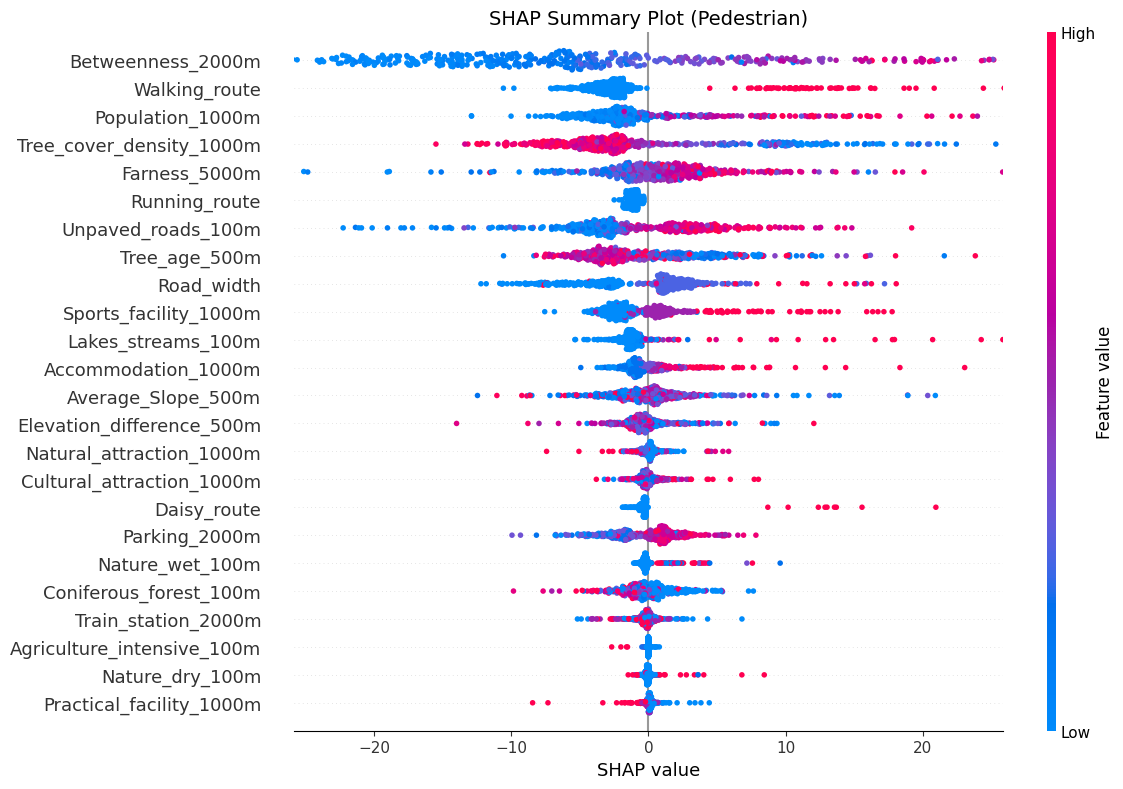

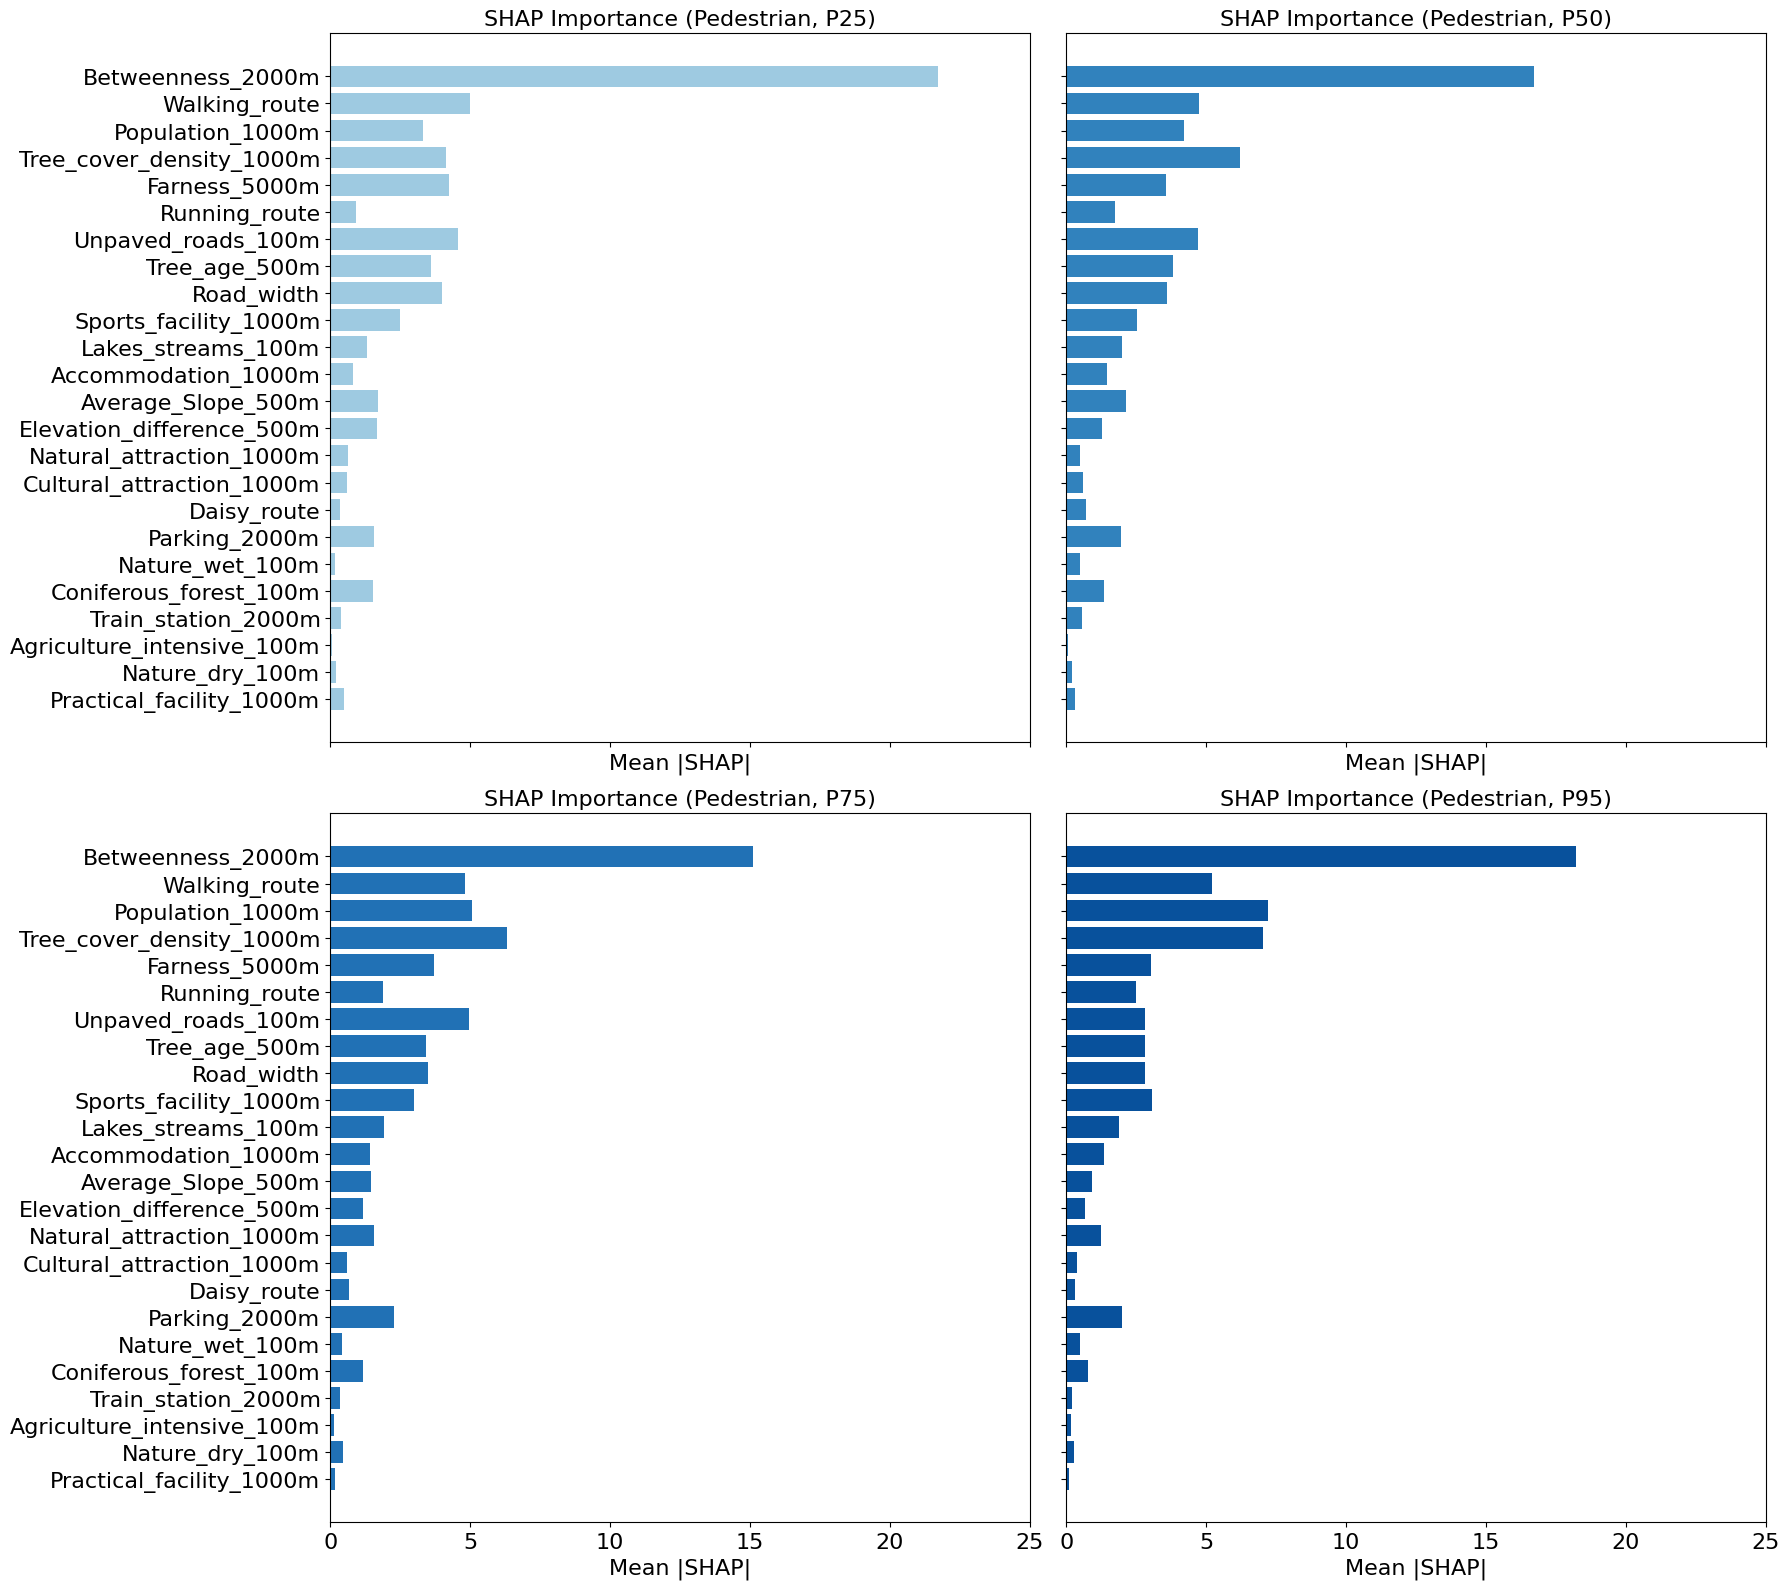


=== SHAP Global Importance - XGBoost P50 (RF order) ===
                       Feature  Mean|SHAP| (P50)  Normalized (%) (P50)  \
6            Betweenness_2000m         41.778656             25.514921   
8                Walking_route         11.850417              7.237247   
14            Population_1000m         10.504394              6.415208   
17    Tree_cover_density_1000m         15.535829              9.487989   
7                Farness_5000m          8.952609              5.467508   
9                Running_route          4.399585              2.686900   
0           Unpaved_roads_100m         11.794521              7.203111   
18               Tree_age_500m          9.503434              5.803906   
11                  Road_width          9.047412              5.525405   
22       Sports_facility_1000m          6.337791              3.870595   
5           Lakes_streams_100m          5.007747              3.058314   
21         Accommodation_1000m          3.666909       

In [39]:
import shap
import math


display_columns = [
    'Unpaved_roads_100m', 'Agriculture_intensive_100m', 'Coniferous_forest_100m', 'Nature_dry_100m', 'Nature_wet_100m', 'Lakes_streams_100m',
    'Betweenness_2000m',
    'Farness_5000m',
    'Walking_route', 'Running_route', 'Daisy_route',
    'Road_width', 'Elevation_difference_500m', 'Average_Slope_500m',
    'Population_1000m','Parking_2000m', 'Train_station_2000m',
    'Tree_cover_density_1000m', 'Tree_age_500m',
    'Practical_facility_1000m', 'Natural_attraction_1000m', 'Accommodation_1000m', 'Sports_facility_1000m', 'Cultural_attraction_1000m'
]
feature_names_human = display_columns

rf_order = importance_df['Feature'].tolist()
rf_order_full = [f for f in rf_order if f in feature_names_human] + \
                [f for f in feature_names_human if f not in rf_order]


models       = joblib.load("xgb_cqr_ped.pkl")        # dict: {0.05,0.25,0.50,0.75,0.95}
scaler_final = joblib.load("scaler_cqr_ped.pkl")
test_indices = joblib.load("test_indices_ped.pkl")

selected_columns = [
    'BM_104_100','BM_201_100','BM_302_100','BM_401_100','BM_402_100','BM_501_100',
    'BtH2000','MHD5000',
    '5_walk_route','2_run_route','13_daisy_route',
    'width','eDiff_500','avgSlope_500',
    'popula_1000m','parking_2000m','train_station_2000m',
    'treecoverden_1000m','tree_age_500m',
    '5_culture_1000m','2_natural_1000m','3_accommodation_1000m','4_sports_1000m','1_practical_1000m'
]
features = [c for c in selected_columns if c in dataset.columns]

def subset_by_indices(df, indices):
    indices = np.asarray(indices)
    if indices.dtype == bool:
        return df.loc[indices]
    try:
        return df.loc[indices]
    except Exception:
        return df.iloc[indices]

X_test = subset_by_indices(dataset[features], test_indices)
y_test = subset_by_indices(dataset['ped_avg'], test_indices)

x_test_scaled = scaler_final.transform(X_test)
y_test_np = np.asarray(y_test)


y_pred50 = models[0.50].predict(x_test_scaled)
r2_50 = r2_score(y_test_np, y_pred50)
print("Test R² (P50):", r2_50)


def shap_adjusted_importance(model, X, names, r2_ref):
    exp = shap.TreeExplainer(model)
    sv  = exp.shap_values(X)
    mabs = np.abs(sv).mean(axis=0)
    denom = mabs.sum()
    norm = mabs / denom * 100 if denom > 0 else np.zeros_like(mabs)
    adj  = norm * r2_ref
    return sv, mabs, pd.DataFrame({'Feature': names, 'Adjusted by R^2 (%)': adj})


xgb_p50 = models[0.50]
explainer_p50 = shap.TreeExplainer(xgb_p50)
sv_p50 = explainer_p50.shap_values(x_test_scaled)

mabs = np.abs(sv_p50).mean(axis=0)
total_mabs = mabs.sum()
scale = (100.0 * r2_50) / total_mabs if total_mabs > 0 else 0.0
sv_p50_adj = sv_p50 * scale


name_to_idx = {n: i for i, n in enumerate(feature_names_human)}
idx = [name_to_idx[n] for n in rf_order_full]
sv_vis = sv_p50_adj[:, idx]
X_vis  = x_test_scaled[:, idx]
names_vis = [feature_names_human[i] for i in idx]

shap.summary_plot(
    sv_vis, X_vis,
    feature_names=names_vis,
    plot_size=(12, 8),
    max_display=len(names_vis),
    sort=False,
    show=False
)
plt.xlabel("SHAP value", fontsize=13)

lim = np.percentile(np.abs(sv_vis), 99)
if np.isfinite(lim) and lim > 0:
    plt.xlim(-lim, lim)

plt.title("SHAP Summary Plot (Pedestrian)", fontsize=14)
plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/feature selection/SHAP_beeswarm_xgb_P50.png",
    dpi=300, bbox_inches='tight'
)
plt.show()


sv25, m25, df25 = shap_adjusted_importance(models[0.25], x_test_scaled, feature_names_human, r2_50)
sv50, m50, df50 = shap_adjusted_importance(models[0.50], x_test_scaled, feature_names_human, r2_50)
sv75, m75, df75 = shap_adjusted_importance(models[0.75], x_test_scaled, feature_names_human, r2_50)
sv95, m95, df95 = shap_adjusted_importance(models[0.95], x_test_scaled, feature_names_human, r2_50)

compare_df = (df50.rename(columns={'Adjusted by R^2 (%)': 'P50'})
                .merge(df25.rename(columns={'Adjusted by R^2 (%)': 'P25'}), on='Feature')
                .merge(df75.rename(columns={'Adjusted by R^2 (%)': 'P75'}), on='Feature')
                .merge(df95.rename(columns={'Adjusted by R^2 (%)': 'P95'}), on='Feature'))


compare_df['Feature'] = pd.Categorical(
    compare_df['Feature'],
    categories=list(reversed(rf_order_full)),
    ordered=True
)
compare_df = compare_df.sort_values('Feature')

def _nice_step(maxv, n_ticks=5):
    if maxv <= 0 or not np.isfinite(maxv):
        return 1.0
    raw = maxv / n_ticks
    exp = 10 ** math.floor(math.log10(raw))
    frac = raw / exp
    if frac <= 1:   nice = 1
    elif frac <= 2: nice = 2
    elif frac <= 5: nice = 5
    else:           nice = 10
    return nice * exp

xmax = float(compare_df[['P25','P50','P75','P95']].to_numpy().max())
xmax = xmax * 1.01 if np.isfinite(xmax) and xmax > 0 else 1.0
step = _nice_step(xmax, n_ticks=5)
tick_max = step * math.ceil(xmax / step)
ticks = np.arange(0, tick_max + 0.5 * step, step)

fig, axes = plt.subplots(2, 2, figsize=(18, 16), sharey=True, sharex=True)
xlabel_text = "Mean |SHAP|"
FONT = 16


axes[0, 0].barh(compare_df['Feature'], compare_df['P25'], color="#9ecae1")
axes[0, 0].set_title("SHAP Importance (Pedestrian, P25)", fontsize=FONT)
axes[0, 0].set_xlabel(xlabel_text, fontsize=FONT)

axes[0, 1].barh(compare_df['Feature'], compare_df['P50'], color="#3182bd")
axes[0, 1].set_title("SHAP Importance (Pedestrian, P50)", fontsize=FONT)
axes[0, 1].set_xlabel(xlabel_text, fontsize=FONT)


axes[1, 0].barh(compare_df['Feature'], compare_df['P75'], color="#2171b5")
axes[1, 0].set_title("SHAP Importance (Pedestrian, P75)", fontsize=FONT)
axes[1, 0].set_xlabel(xlabel_text, fontsize=FONT)

axes[1, 1].barh(compare_df['Feature'], compare_df['P95'], color="#08519c")
axes[1, 1].set_title("SHAP Importance (Pedestrian, P95)", fontsize=FONT)
axes[1, 1].set_xlabel(xlabel_text, fontsize=FONT)

for ax in axes.ravel():
    ax.set_xlim(0, tick_max)
    ax.set_xticks(ticks)
    ax.tick_params(axis='x', labelsize=FONT)
    ax.tick_params(axis='y', labelsize=FONT)

plt.tight_layout()
plt.savefig(
    "/Users/wmv973/OneDrive - University of Copenhagen/Output/VisualPaper1/YearlyPed/feature selection/Feature_importance_ped_xgb.png",
    dpi=300, bbox_inches='tight'
)
plt.show()


importance_p50 = pd.DataFrame({
    'Feature': feature_names_human,
    'Mean|SHAP| (P50)': m50,
}).assign(**{
    'Normalized (%) (P50)': lambda d: d['Mean|SHAP| (P50)']/d['Mean|SHAP| (P50)'].sum()*100 if d['Mean|SHAP| (P50)'].sum() > 0 else 0,
    'Adjusted by R^2 (%) (P50)': lambda d: d['Normalized (%) (P50)']*r2_50
})

importance_p50['Feature'] = pd.Categorical(importance_p50['Feature'], categories=rf_order_full, ordered=True)
importance_p50 = importance_p50.sort_values('Feature')

print("\n=== SHAP Global Importance - XGBoost P50 (RF order) ===")
print(importance_p50[['Feature','Mean|SHAP| (P50)','Normalized (%) (P50)','Adjusted by R^2 (%) (P50)']])